In [ ]:
import os, shutil, subprocess, sys
from pathlib import Path

ROOT = Path('/content' if os.path.isdir('/content') else '.')
RAR_PATH = ROOT / 'BurnedAreaUAV_dataset_v1.rar'
DATA_DIR = ROOT / 'BurnedAreaUAV_dataset'

# Remove stale artifacts (comment out if you want to keep them between runs)
if RAR_PATH.exists():
    RAR_PATH.unlink()
if DATA_DIR.exists():
    shutil.rmtree(DATA_DIR)

print('Clean state ready at:', ROOT.resolve())

Clean state ready at: /content


## 2. Download the dataset from Zenodo

Total size: ~870 MB. We use `wget -c` so a partial download can be
resumed by re-running the cell.

In [ ]:
URL = 'https://zenodo.org/records/7944963/files/BurnedAreaUAV_dataset_v1.rar?download=1'

# Skip if already downloaded (e.g. on re-run)
if RAR_PATH.exists() and RAR_PATH.stat().st_size > 800 * 1024 * 1024:
    print(f'Reusing existing {RAR_PATH} ({RAR_PATH.stat().st_size / 1024 / 1024:.1f} MB)')
else:
    !wget -c -O "{RAR_PATH}" "{URL}"


# Sanity check
size_mb = RAR_PATH.stat().st_size / (1024 * 1024)
print(f'Downloaded file size: {size_mb:.1f} MB')
assert size_mb > 800, 'Download appears truncated — re-run previous cell to resume.'

--2026-08-07 12:51:40--  https://zenodo.org/records/7944963/files/BurnedAreaUAV_dataset_v1.rar?download=1
Resolving zenodo.org (zenodo.org)... 188.184.98.114, 188.185.48.75, 137.138.52.235, ...
Connecting to zenodo.org (zenodo.org)|188.184.98.114|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 910733585 (869M) [application/octet-stream]
Saving to: ‘/content/BurnedAreaUAV_dataset_v1.rar’

/content/BurnedArea 100%[===================>] 868.54M  2.62MB/s    in 6m 52s  

2026-08-07 12:58:33 (2.11 MB/s) - ‘/content/BurnedAreaUAV_dataset_v1.rar’ saved [910733585/910733585]

Downloaded file size: 868.5 MB


## 3. Extract the RAR archive

The archive is RAR5, so we need a recent `unrar` binary.

In [ ]:
def have(cmd):
    return shutil.which(cmd) is not None

if have('unrar'):
    EXTRACT_CMD = ['unrar', 'x', '-o+']
    print('Using system unrar')
elif have('unar'):
    EXTRACT_CMD = ['unar', '-f']
    print('Using unar')
else:
    print('No unrar/unar found. Building unrar from source ...')
    src = ROOT / 'unrarsrc'
    if not src.exists():
        subprocess.check_call([
            'curl', '-sL',
            'https://www.rarlab.com/rar/unrarsrc-7.2.6.tar.gz',
            '-o', 'unrarsrc.tar.gz'
        ])
        import tarfile
        with tarfile.open('unrarsrc.tar.gz') as t:
            t.extractall(ROOT)
    subprocess.check_call(['make', '-C', str(src / 'unrar'), '-j4'])
    EXTRACT_CMD = [str(src / 'unrar' / 'unrar'), 'x', '-o+']
    print('Built unrar at:', EXTRACT_CMD[0])


subprocess.check_call(EXTRACT_CMD + [str(RAR_PATH)], cwd=str(ROOT))
print('Extraction done.')

Using system unrar
Extraction done.


## 4. Print the folder / subfolder / image tree

In [ ]:
# @title
def human_size(num):
    for unit in ['B', 'KB', 'MB', 'GB']:
        if num < 1024:
            return f'{num:.1f} {unit}'
        num /= 1024
    return f'{num:.1f} TB'

def print_tree(root):
    print('=' * 90)
    print(f'BurnedAreaUAV dataset  -  root: {root}')
    print('=' * 90)
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames.sort(); filenames.sort()
        rel = os.path.relpath(dirpath, root)
        depth = 0 if rel == '.' else rel.count(os.sep) + 1
        indent = '  ' * depth
        name = os.path.basename(dirpath) if rel != '.' else root.name
        n_files = len(filenames)
        total = sum(os.path.getsize(os.path.join(dirpath, f)) for f in filenames)
        print(f'{indent}<DIR> {name}   ({n_files} files, {human_size(total)})')
        findent = '  ' * (depth + 1)
        for i, f in enumerate(filenames):
            if i >= 6:
                print(f'{findent}... and {n_files - 6} more files')
                break
            p = os.path.join(dirpath, f)
            print(f'{findent}{f}  ({human_size(os.path.getsize(p))})')

print_tree(DATA_DIR)

BurnedAreaUAV dataset  -  root: /content/BurnedAreaUAV_dataset
<DIR> BurnedAreaUAV_dataset   (0 files, 0.0 B)
  <DIR> JSON   (0 files, 0.0 B)
    <DIR> test_json   (23 files, 35.2 MB)
      frame_020250.json  (1.5 MB)
      frame_020350.json  (1.5 MB)
      frame_020450.json  (1.5 MB)
      frame_020550.json  (1.6 MB)
      frame_020650.json  (1.5 MB)
      frame_020750.json  (1.6 MB)
      ... and 17 more files
    <DIR> train_valid_json   (226 files, 365.2 MB)
      frame_000000.json  (1.6 MB)
      frame_000100.json  (1.7 MB)
      frame_000200.json  (1.6 MB)
      frame_000300.json  (1.6 MB)
      frame_000400.json  (1.6 MB)
      frame_000500.json  (1.6 MB)
      ... and 220 more files
  <DIR> MP4_video   (1 files, 222.6 MB)
    original_prescribed_burn_video.mp4  (222.6 MB)
  <DIR> PNG   (0 files, 0.0 B)
    <DIR> test   (0 files, 0.0 B)
      <DIR> frames   (23 files, 36.4 MB)
        frame_020250.png  (1.5 MB)
        frame_020350.png  (1.5 MB)
        frame_020450.png  (1.5 MB

## 5. Pair frames with their masks

In [ ]:
def pair_samples():
    pairs = []
    for split in ['train', 'test']:
        frames_dir = DATA_DIR / 'PNG' / split / 'frames'
        masks_dir  = DATA_DIR / 'PNG' / split / 'msks'
        if not frames_dir.exists() or not masks_dir.exists():
            continue
        frames = sorted(frames_dir.glob('frame_*.png'))
        masks  = sorted(masks_dir.glob('mask_*.png'))
        for f, m in zip(frames, masks):
            pairs.append((split, f, m))
    return pairs

pairs = pair_samples()
n_train = sum(1 for p in pairs if p[0] == 'train')
n_test  = sum(1 for p in pairs if p[0] == 'test')
print(f'Found {len(pairs)} image-mask pairs')
print(f'  train: {n_train}')
print(f'  test : {n_test}')

Found 249 image-mask pairs
  train: 226
  test : 23


## 6. Plot sample images with their masks

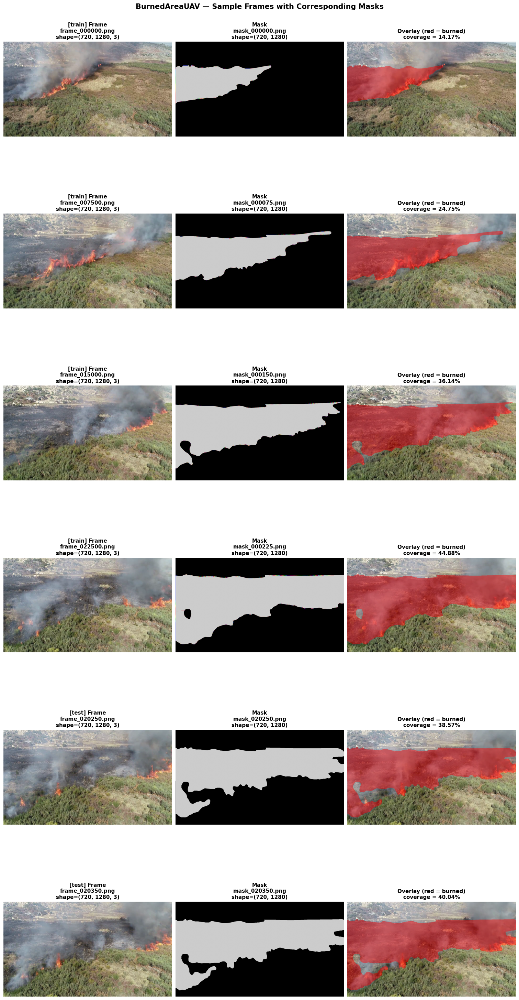

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

try:
    import matplotlib.font_manager as fm
    for fp in ['/usr/share/fonts/truetype/chinese/NotoSansSC-Regular.ttf',
               '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf']:
        if os.path.exists(fp):
            fm.fontManager.addfont(fp)
    plt.rcParams['font.sans-serif'] = ['Noto Sans SC', 'DejaVu Sans']
except Exception:
    pass
plt.rcParams['axes.unicode_minus'] = False


def plot_samples(pairs, n_samples=6):
    n_samples = min(n_samples, len(pairs))
    if n_samples == 0:
        print('No pairs to plot.')
        return
    train_pairs = [p for p in pairs if p[0] == 'train']
    test_pairs  = [p for p in pairs if p[0] == 'test']
    selected = []
    if train_pairs:
        idxs = np.linspace(0, len(train_pairs) - 1,
                           num=min(4, len(train_pairs)), dtype=int)
        selected.extend(train_pairs[i] for i in idxs)
    if test_pairs:
        selected.extend(test_pairs[:2])
    selected = selected[:n_samples]

    n = len(selected)
    fig, axes = plt.subplots(n, 3, figsize=(15, 5 * n), constrained_layout=True)
    if n == 1:
        axes = axes[np.newaxis, :]

    for row, (split, frame_path, mask_path) in enumerate(selected):
        frame = np.array(Image.open(frame_path).convert('RGB'))
        mask  = np.array(Image.open(mask_path))
        mask_bin = (mask > 0).astype(np.uint8) if mask.ndim == 2 \
                   else (mask.sum(axis=2) > 0).astype(np.uint8)

        axes[row, 0].imshow(frame)
        axes[row, 0].set_title(f'[{split}] Frame\n{frame_path.name}\nshape={frame.shape}',
                               fontsize=11, fontweight='bold')
        axes[row, 0].axis('off')

        axes[row, 1].imshow(mask, cmap='nipy_spectral',
                            vmin=0, vmax=max(int(mask.max()), 1))
        axes[row, 1].set_title(f'Mask\n{mask_path.name}\nshape={mask.shape}',
                               fontsize=11, fontweight='bold')
        axes[row, 1].axis('off')

        overlay = frame.copy().astype(np.float32)
        red = np.zeros_like(overlay); red[..., 0] = 255.0
        alpha = 0.45 * mask_bin[..., None]
        overlay = overlay * (1 - alpha) + red * alpha
        overlay = np.clip(overlay, 0, 255).astype(np.uint8)
        axes[row, 2].imshow(overlay)
        axes[row, 2].set_title(f'Overlay (red = burned)\ncoverage = '
                               f'{mask_bin.mean() * 100:.2f}%',
                               fontsize=11, fontweight='bold')
        axes[row, 2].axis('off')

    fig.suptitle('BurnedAreaUAV — Sample Frames with Corresponding Masks',
                 fontsize=15, fontweight='bold', y=1.0)
    plt.show()

plot_samples(pairs, n_samples=6)

## 7. Compact overview grid (16 train samples)

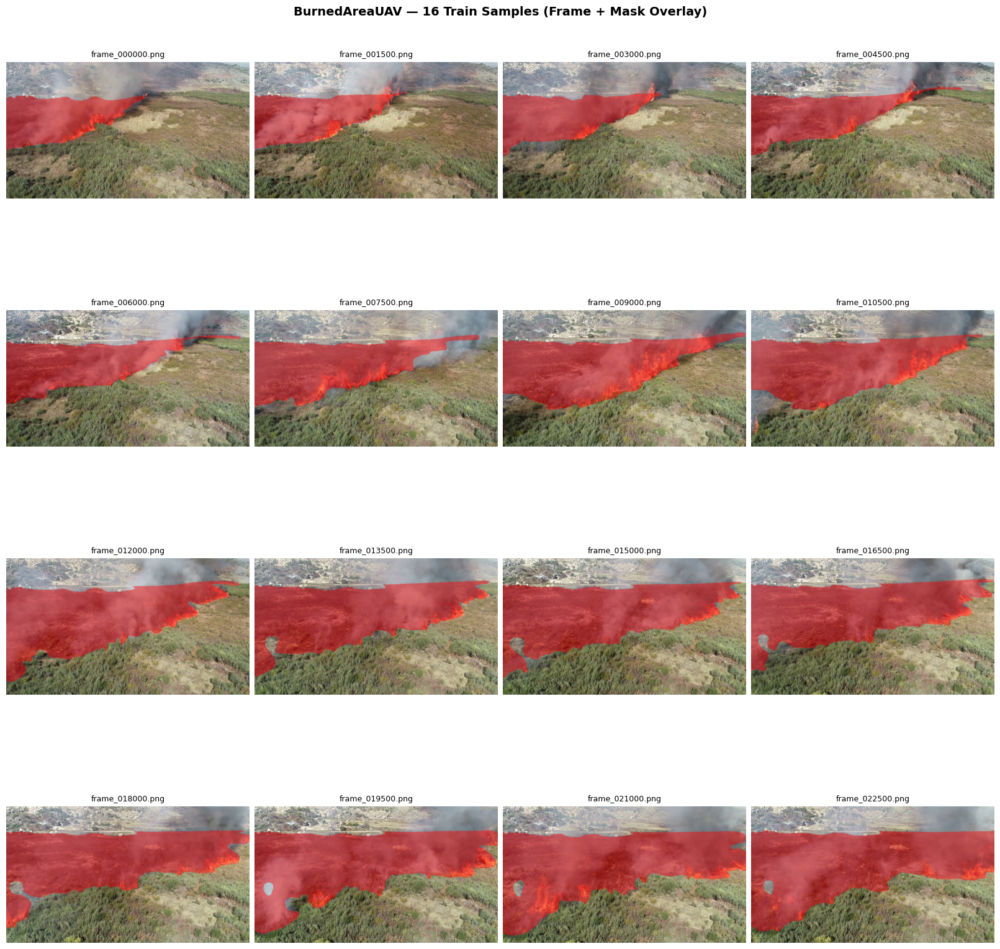

In [ ]:
def plot_grid_overview(pairs, n=16):
    train_pairs = [p for p in pairs if p[0] == 'train']
    if not train_pairs:
        print('No train pairs to plot.')
        return
    n = min(n, len(train_pairs))
    idxs = np.linspace(0, len(train_pairs) - 1, num=n, dtype=int)
    selected = [train_pairs[i] for i in idxs]

    cols = 4
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4),
                             constrained_layout=True)
    axes = np.array(axes).flatten()
    for ax, (split, frame_path, mask_path) in zip(axes, selected):
        frame = np.array(Image.open(frame_path).convert('RGB'))
        mask  = np.array(Image.open(mask_path))
        mask_bin = (mask > 0).astype(np.uint8) if mask.ndim == 2 \
                   else (mask.sum(axis=2) > 0).astype(np.uint8)
        overlay = frame.copy().astype(np.float32)
        red = np.zeros_like(overlay); red[..., 0] = 255.0
        alpha = 0.45 * mask_bin[..., None]
        overlay = overlay * (1 - alpha) + red * alpha
        overlay = np.clip(overlay, 0, 255).astype(np.uint8)
        ax.imshow(overlay)
        ax.set_title(frame_path.name, fontsize=9)
        ax.axis('off')
    for ax in axes[len(selected):]:
        ax.axis('off')
    fig.suptitle('BurnedAreaUAV — 16 Train Samples (Frame + Mask Overlay)',
                 fontsize=14, fontweight='bold', y=1.0)
    plt.show()

plot_grid_overview(pairs, n=16)

## 8. Bonus: burned-area coverage histogram

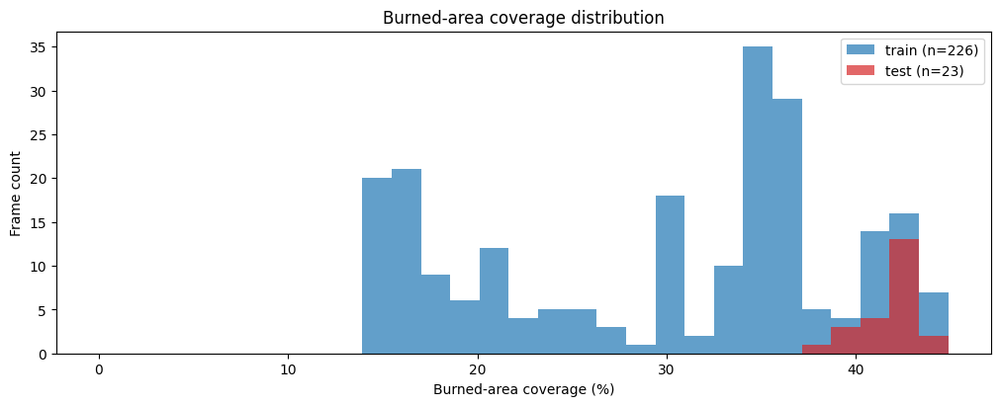

Train coverage  — mean 29.80%  median 33.80%  max 44.88%
Test  coverage  — mean 41.81%  median 42.45%  max 43.45%


In [ ]:
coverages = []
for split, frame_path, mask_path in pairs:
    mask = np.array(Image.open(mask_path))
    mask_bin = (mask > 0).astype(np.uint8) if mask.ndim == 2 \
               else (mask.sum(axis=2) > 0).astype(np.uint8)
    coverages.append((split, mask_bin.mean() * 100))

train_c = [c for s, c in coverages if s == 'train']
test_c  = [c for s, c in coverages if s == 'test']

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
bins = np.linspace(0, max(max(train_c), max(test_c), 1), 30)
ax.hist(train_c, bins=bins, alpha=0.7, label=f'train (n={len(train_c)})', color='#1f77b4')
ax.hist(test_c,  bins=bins, alpha=0.7, label=f'test (n={len(test_c)})',  color='#d62728')
ax.set_xlabel('Burned-area coverage (%)')
ax.set_ylabel('Frame count')
ax.set_title('Burned-area coverage distribution')
ax.legend()
plt.show()

print(f'Train coverage  — mean {np.mean(train_c):.2f}%  '
      f'median {np.median(train_c):.2f}%  max {max(train_c):.2f}%')
print(f'Test  coverage  — mean {np.mean(test_c):.2f}%  '
      f'median {np.median(test_c):.2f}%  max {max(test_c):.2f}%')

# 2nd dataset

The Fairdata download link is token-based and expires every 72 hours.
The Fairdata download link is token-based and expires every 72 hours. Therefore, whenever the link expires, please open the dataset page again, generate a fresh download link, and replace only the URL inside the wget --content-disposition "..." command. No other code changes are required.(https://etsin.fairdata.fi/dataset/1dce1023-493a-4d63-a906-f2a44f831898/data) go this site and under data section there will be manjor folder in that while u expand u will see the subset-c ul will obserbe the download option on that click on 3 dots will see some option select the wget link select taht and paste in below cell in url

In [ ]:
import os
from pathlib import Path

DOWNLOAD_DIR = Path("/content/boreal_selected_folder")
DOWNLOAD_DIR.mkdir(parents=True, exist_ok=True)

# Fairdata download tokens expire. Open the dataset page, select Subset-C,
# copy its current wget link, and paste only the URL when prompted.
url = input("Paste the fresh Fairdata Subset-C download URL: ").strip().strip('"').strip("'")
if not url.startswith("https://download.fairdata.fi/download?token="):
    raise ValueError("Expected a fresh Fairdata download URL containing ?token=.")

!wget -c --content-disposition -P "{DOWNLOAD_DIR}" "{url}"


In [ ]:
from pathlib import Path

downloaded_files = list(DOWNLOAD_DIR.glob("*"))

print("Downloaded files:")
for f in downloaded_files:
    print(f.name, "->", round(f.stat().st_size / (1024**2), 2), "MB")

zip_files = list(DOWNLOAD_DIR.glob("*.zip"))

if len(zip_files) == 0:
    raise FileNotFoundError("No ZIP file found. Check whether the download completed correctly.")

ZIP_PATH = zip_files[0]
print("Selected ZIP:", ZIP_PATH)

import zipfile

EXTRACT_DIR = DOWNLOAD_DIR / "extracted"
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction completed.")
print("Extracted path:", EXTRACT_DIR)

def print_folder_tree(root_dir, max_depth=5):
    root_dir = Path(root_dir)
    root_depth = len(root_dir.parts)

    for path in sorted(root_dir.rglob("*")):
        depth = len(path.parts) - root_depth
        if depth > max_depth:
            continue

        indent = "    " * depth
        if path.is_dir():
            print(f"{indent}📁 {path.name}")
        else:
            print(f"{indent}📄 {path.name}")

print_folder_tree(EXTRACT_DIR, max_depth=5)

Downloaded files:
1dce1023-493a-4d63-a906-f2a44f831898_1wvdi0u1.zip -> 456.83 MB
Selected ZIP: /content/boreal_selected_folder/1dce1023-493a-4d63-a906-f2a44f831898_1wvdi0u1.zip
Extraction completed.
Extracted path: /content/boreal_selected_folder/extracted
    📁 Boreal-Forest-Fire
        📁 Boreal-Forest-Fire-Subset-C
            📁 images
                📁 test
                    📄 evoDJI_0001_frame123.jpg
                    📄 evoDJI_0001_frame128.jpg
                    📄 evoDJI_0001_frame136.jpg
                    📄 evoDJI_0001_frame143.jpg
                    📄 evoDJI_0007_frame138.jpg
                    📄 evoDJI_0007_frame148.jpg
                    📄 evoDJI_0007_frame149.jpg
                    📄 evoDJI_0007_frame151.jpg
                    📄 evoDJI_0007_frame155.jpg
                    📄 evoDJI_0007_frame163.jpg
                    📄 evoDJI_0009_frame113.jpg
                    📄 evoDJI_0009_frame116.jpg
                    📄 evoDJI_0009_frame132.jpg
                    📄 evo

,Total files,Total images,Raw images,Mask/annotation images,Videos,CSV files,JSON files,Total folders
0,4392,2929,1472,1457,0,0,0,16


,Folder/Class,Number of Images
0,Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C...,1184
4,Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C...,1150
1,Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C...,248
5,Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C...,227
2,Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C...,40
3,Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C...,40
6,Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C...,40


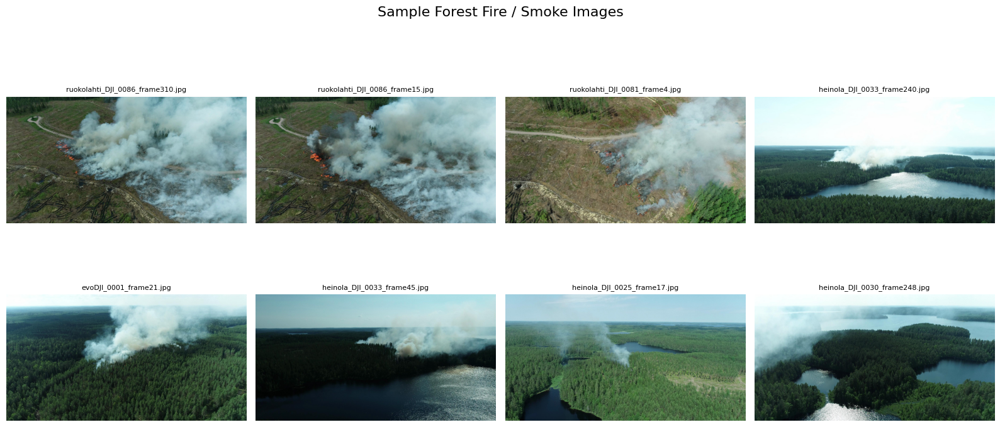

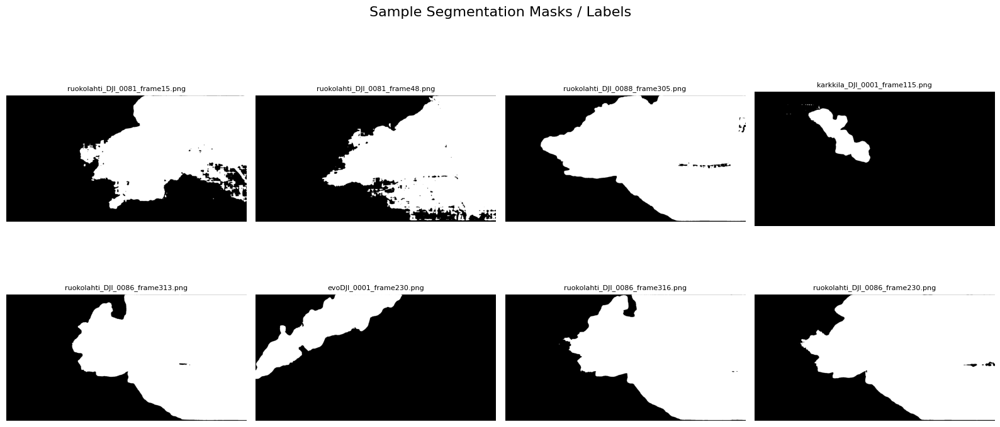

In [ ]:
import pandas as pd
from collections import Counter

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
VIDEO_EXTS = {".mp4", ".avi", ".mov", ".mkv"}
CSV_EXTS = {".csv"}
JSON_EXTS = {".json"}

all_files = [p for p in EXTRACT_DIR.rglob("*") if p.is_file()]
image_files = [p for p in all_files if p.suffix.lower() in IMAGE_EXTS]
video_files = [p for p in all_files if p.suffix.lower() in VIDEO_EXTS]
csv_files = [p for p in all_files if p.suffix.lower() in CSV_EXTS]
json_files = [p for p in all_files if p.suffix.lower() in JSON_EXTS]

mask_keywords = ["mask", "label", "labels", "seg", "segmentation", "annotation", "annotations"]

mask_files = [
    p for p in image_files
    if any(k in str(p).lower() for k in mask_keywords)
]

raw_image_files = [p for p in image_files if p not in mask_files]

summary_df = pd.DataFrame([{
    "Total files": len(all_files),
    "Total images": len(image_files),
    "Raw images": len(raw_image_files),
    "Mask/annotation images": len(mask_files),
    "Videos": len(video_files),
    "CSV files": len(csv_files),
    "JSON files": len(json_files),
    "Total folders": len([p for p in EXTRACT_DIR.rglob("*") if p.is_dir()])
}])

display(summary_df)

folder_counts = Counter()

for img_path in image_files:
    folder_name = str(img_path.parent.relative_to(EXTRACT_DIR))
    folder_counts[folder_name] += 1

folder_df = pd.DataFrame(
    [{"Folder/Class": folder, "Number of Images": count}
     for folder, count in folder_counts.items()]
).sort_values("Number of Images", ascending=False)

display(folder_df)

import random
import matplotlib.pyplot as plt
from PIL import Image

def show_sample_images(files, title="Sample Images", n=8):
    if len(files) == 0:
        print("No images found.")
        return

    sample_files = random.sample(files, min(n, len(files)))

    plt.figure(figsize=(16, 8))

    for i, img_path in enumerate(sample_files):
        try:
            img = Image.open(img_path).convert("RGB")
            plt.subplot(2, 4, i + 1)
            plt.imshow(img)
            plt.title(img_path.name[:35], fontsize=8)
            plt.axis("off")
        except Exception as e:
            print("Could not open:", img_path, e)

    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()

show_sample_images(raw_image_files, title="Sample Forest Fire / Smoke Images", n=8)
show_sample_images(mask_files, title="Sample Segmentation Masks / Labels", n=8)

# Dataset merging and augmentation

In [ ]:
from pathlib import Path
from collections import Counter
import os

BOREAL_SUBSET_C = Path(
    "/content/boreal_selected_folder/extracted/"
    "Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C"
)

if BOREAL_SUBSET_C.exists():
    EXTRACT_DIR = BOREAL_SUBSET_C
    print("✅ Boreal Subset-C folder found:")
    print(EXTRACT_DIR)
else:
    EXTRACT_DIR = Path("/content/boreal_selected_folder/extracted")
    print("⚠ Exact Subset-C folder not found. Using parent folder:")
    print(EXTRACT_DIR)

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

all_files = [p for p in EXTRACT_DIR.rglob("*") if p.is_file()]
image_files = [p for p in all_files if p.suffix.lower() in IMAGE_EXTS]

print("\nTotal files found:", len(all_files))
print("Total image-like files found:", len(image_files))

print("\nFile extension counts:")
for ext, count in Counter(p.suffix.lower() for p in image_files).items():
    print(f"  {ext}: {count}")

print("\nTop-level folders/files:")
for p in sorted(EXTRACT_DIR.iterdir()):
    print("  [DIR] " + p.name if p.is_dir() else "  [FILE] " + p.name)

print("\nPossible mask/label folders:")
mask_words = ["mask", "masks", "label", "labels", "seg", "annotation", "annotations", "gt", "groundtruth"]
for p in EXTRACT_DIR.rglob("*"):
    if p.is_dir() and any(w in p.name.lower() for w in mask_words):
        print("  ", p)

✅ Boreal Subset-C folder found:
/content/boreal_selected_folder/extracted/Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C

Total files found: 4392
Total image-like files found: 2929

File extension counts:
  .jpg: 1472
  .png: 1457

Top-level folders/files:
  [DIR] images
  [DIR] labels
  [DIR] manual_masks
  [DIR] sam_masks

Possible mask/label folders:
   /content/boreal_selected_folder/extracted/Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C/labels
   /content/boreal_selected_folder/extracted/Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C/manual_masks
   /content/boreal_selected_folder/extracted/Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C/sam_masks


Paths configured.
[BurnedAreaUAV] train: images=226, masks=226
[BurnedAreaUAV] test: images=23, masks=23
Total BurnedAreaUAV pairs: 249

[Boreal] Images=1472, Manual masks=40, SAM masks=1417
Matched manual=40, SAM=1377
Final Boreal real pairs: 1417

Boreal split:
train : 1133
val : 141
test : 143

Total: BA=249, Boreal=1417, Total=1666

Combined dataset ready. Saved=1666, Failed=0
train : 1359
val : 141
test : 166


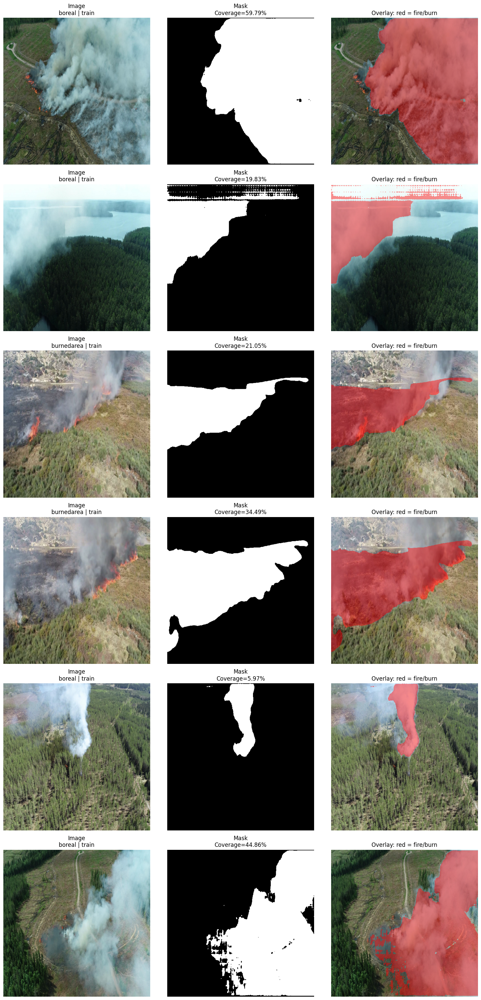


Final augmented dataset ready. Original=1666, Augmented=4077, Total=5743

FINAL DATASET SUMMARY
Split  BurnedAreaUAV Original  BurnedAreaUAV Augmented  Boreal Original  Boreal Augmented  Total
train                     226                      678             1133              3399   5436
  val                       0                        0              141                 0    141
 test                      23                        0              143                 0    166


In [ ]:
'''
FULL SINGLE-BLOCK UPDATED CODE
BurnedAreaUAV + Boreal-Forest-Fire-Subset-C
'''

import os
import re
import cv2
import shutil
import random
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
from PIL import Image, ImageEnhance, ImageFilter
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path("/content")
DATA_DIR = ROOT / "BurnedAreaUAV_dataset"
BOREAL_SUBSET_C = Path(
    "/content/boreal_selected_folder/extracted/"
    "Boreal-Forest-Fire/Boreal-Forest-Fire-Subset-C"
)
COMBINED_DIR = ROOT / "combined_dataset"
AUGMENTED_DIR = ROOT / "final_augmented_dataset"

TARGET_SIZE = (512, 512)
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
AUGMENTATIONS_PER_IMAGE = 3
RESET_OUTPUT_DIRS = True

if RESET_OUTPUT_DIRS:
    for d in [COMBINED_DIR, AUGMENTED_DIR]:
        if d.exists():
            shutil.rmtree(d)

for base_dir in [COMBINED_DIR, AUGMENTED_DIR]:
    for split in ["train", "val", "test"]:
        (base_dir / split / "images").mkdir(parents=True, exist_ok=True)
        (base_dir / split / "masks").mkdir(parents=True, exist_ok=True)

print("Paths configured.")


def collect_burnedarea_pairs(data_dir):
    pairs = []
    for split in ["train", "test"]:
        frames_dir = data_dir / "PNG" / split / "frames"
        masks_dir = data_dir / "PNG" / split / "msks"
        if not frames_dir.exists() or not masks_dir.exists():
            continue
        frames = sorted(frames_dir.glob("frame_*.png"))
        masks = sorted(masks_dir.glob("mask_*.png"))
        print(f"[BurnedAreaUAV] {split}: images={len(frames)}, masks={len(masks)}")
        for img_path, mask_path in zip(frames, masks):
            pairs.append({"source": "burnedarea", "split": split,
                          "image": img_path, "mask": mask_path, "mask_type": "manual"})
    return pairs


ba_pairs = collect_burnedarea_pairs(DATA_DIR)
print("Total BurnedAreaUAV pairs:", len(ba_pairs))


def normalize_name(name):
    name = name.lower()
    for token in ["_mask","-mask","mask_","_masks","-masks","masks_","_manual",
                  "-manual","manual_","_sam","-sam","sam_","_label","-label",
                  "label_","_labels","-labels","labels_","_gt","-gt","gt_",
                  "_annotation","-annotation","annotation_","_groundtruth",
                  "-groundtruth","groundtruth_","_target","-target","target_"]:
        name = name.replace(token, "")
    name = re.sub(r"[^a-z0-9]", "", name)
    return name


def match_masks_to_images(image_files, mask_files, mask_type, used_images=None):
    if used_images is None:
        used_images = set()
    pairs = []
    current_used = set()
    exact_lookup = defaultdict(list)
    normal_lookup = defaultdict(list)
    for img in image_files:
        if img in used_images:
            continue
        exact_lookup[img.stem.lower()].append(img)
        normal_lookup[normalize_name(img.stem)].append(img)
    for mask in mask_files:
        key = mask.stem.lower()
        for img in exact_lookup.get(key, []):
            if img not in used_images and img not in current_used:
                pairs.append({"source": "boreal", "split": "train",
                               "image": img, "mask": mask, "mask_type": mask_type})
                current_used.add(img)
                break
    matched_masks = set(p["mask"] for p in pairs)
    for mask in mask_files:
        if mask in matched_masks:
            continue
        key = normalize_name(mask.stem)
        for img in normal_lookup.get(key, []):
            if img not in used_images and img not in current_used:
                pairs.append({"source": "boreal", "split": "train",
                               "image": img, "mask": mask, "mask_type": mask_type})
                current_used.add(img)
                break
    return pairs, current_used


def collect_boreal_pairs(subset_dir):
    images_dir = subset_dir / "images"
    manual_masks_dir = subset_dir / "manual_masks"
    sam_masks_dir = subset_dir / "sam_masks"
    if not images_dir.exists():
        raise FileNotFoundError(f"Images folder not found: {images_dir}")
    image_files = sorted([p for p in images_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS])
    manual_masks = sorted([p for p in manual_masks_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]) if manual_masks_dir.exists() else []
    sam_masks = sorted([p for p in sam_masks_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS]) if sam_masks_dir.exists() else []
    print(f"\n[Boreal] Images={len(image_files)}, Manual masks={len(manual_masks)}, SAM masks={len(sam_masks)}")
    all_pairs = []
    used_images = set()
    manual_pairs, used_manual = match_masks_to_images(image_files, manual_masks, "manual_masks", used_images)
    all_pairs.extend(manual_pairs)
    used_images.update(used_manual)
    sam_pairs, used_sam = match_masks_to_images(image_files, sam_masks, "sam_masks", used_images)
    all_pairs.extend(sam_pairs)
    used_images.update(used_sam)
    print(f"Matched manual={len(manual_pairs)}, SAM={len(sam_pairs)}")
    if len(all_pairs) == 0:
        print("No pairs matched. Trying positional fallback.")
        mask_files_fb = manual_masks if manual_masks else sam_masks
        mask_type_fb = "manual_masks_positional" if manual_masks else "sam_masks_positional"
        for img, mask in zip(image_files, mask_files_fb):
            all_pairs.append({"source": "boreal", "split": "train",
                               "image": img, "mask": mask, "mask_type": mask_type_fb})
    print("Final Boreal real pairs:", len(all_pairs))
    return all_pairs


boreal_pairs = collect_boreal_pairs(BOREAL_SUBSET_C)


def split_boreal_records(records, train_ratio=0.80, val_ratio=0.10):
    records = records.copy()
    random.shuffle(records)
    n = len(records)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)
    train_records = records[:n_train]
    val_records = records[n_train:n_train + n_val]
    test_records = records[n_train + n_val:]
    for r in train_records: r["split"] = "train"
    for r in val_records: r["split"] = "val"
    for r in test_records: r["split"] = "test"
    return train_records + val_records + test_records


boreal_pairs = split_boreal_records(boreal_pairs)
print("\nBoreal split:")
for split in ["train", "val", "test"]:
    print(split, ":", sum(1 for p in boreal_pairs if p["split"] == split))


def load_and_resize_image(path, size=TARGET_SIZE):
    img = Image.open(path).convert("RGB")
    img = img.resize(size, Image.BILINEAR)
    return np.array(img)


def load_and_resize_mask(path, size=TARGET_SIZE):
    mask = Image.open(path).convert("L")
    mask = mask.resize(size, Image.NEAREST)
    mask_arr = np.array(mask)
    mask_arr = (mask_arr > 0).astype(np.uint8) * 255
    return mask_arr


all_pairs = ba_pairs + boreal_pairs
print(f"\nTotal: BA={len(ba_pairs)}, Boreal={len(boreal_pairs)}, Total={len(all_pairs)}")

combined_records = []
failed = 0

for idx, pair in enumerate(all_pairs):
    try:
        img_arr = load_and_resize_image(pair["image"])
        mask_arr = load_and_resize_mask(pair["mask"])
        src_tag = "BA" if pair["source"] == "burnedarea" else "BO"
        split = pair["split"]
        stem = f"{src_tag}_{idx:05d}"
        img_save_path = COMBINED_DIR / split / "images" / f"{stem}.png"
        mask_save_path = COMBINED_DIR / split / "masks" / f"{stem}.png"
        Image.fromarray(img_arr.astype(np.uint8)).save(img_save_path)
        Image.fromarray(mask_arr.astype(np.uint8)).save(mask_save_path)
        combined_records.append({"image": img_save_path, "mask": mask_save_path,
                                  "source": pair["source"], "split": split,
                                  "mask_type": pair.get("mask_type", "manual"),
                                  "original_image": str(pair["image"]),
                                  "original_mask": str(pair["mask"])})
    except Exception as e:
        failed += 1
        print("Skipped:", pair["image"], e)

print(f"\nCombined dataset ready. Saved={len(combined_records)}, Failed={failed}")
for split in ["train", "val", "test"]:
    print(split, ":", sum(1 for r in combined_records if r["split"] == split))

metadata = pd.DataFrame(combined_records)
metadata.to_csv(COMBINED_DIR / "combined_metadata.csv", index=False)


def plot_samples(records, n=6):
    if len(records) == 0:
        return
    sample = random.sample(records, min(n, len(records)))
    fig, axes = plt.subplots(len(sample), 3, figsize=(15, 5 * len(sample)))
    if len(sample) == 1:
        axes = axes[np.newaxis, :]
    for i, rec in enumerate(sample):
        img = np.array(Image.open(rec["image"]).convert("RGB"))
        mask = np.array(Image.open(rec["mask"]).convert("L"))
        mask_bin = (mask > 0).astype(np.uint8)
        overlay = img.copy().astype(np.float32)
        red = np.zeros_like(overlay); red[..., 0] = 255
        alpha = 0.45 * mask_bin[..., np.newaxis]
        overlay = np.clip(overlay * (1 - alpha) + red * alpha, 0, 255).astype(np.uint8)
        coverage = mask_bin.mean() * 100
        axes[i, 0].imshow(img); axes[i, 0].set_title(f"Image\n{rec['source']} | {rec['split']}"); axes[i, 0].axis("off")
        axes[i, 1].imshow(mask, cmap="gray"); axes[i, 1].set_title(f"Mask\nCoverage={coverage:.2f}%"); axes[i, 1].axis("off")
        axes[i, 2].imshow(overlay); axes[i, 2].set_title("Overlay: red = fire/burn"); axes[i, 2].axis("off")
    plt.tight_layout(); plt.show()


plot_samples(combined_records, n=6)


def aug_horizontal_flip(image, mask):
    return image[:, ::-1].copy(), mask[:, ::-1].copy()

def aug_vertical_flip(image, mask):
    return image[::-1].copy(), mask[::-1].copy()

def aug_rotate(image, mask):
    angle = random.choice([90, 180, 270])
    k = angle // 90
    return np.rot90(image, k).copy(), np.rot90(mask, k).copy()

def aug_random_crop_resize(image, mask, crop_frac_range=(0.70, 0.95)):
    h, w = image.shape[:2]
    frac = random.uniform(*crop_frac_range)
    ch, cw = int(h * frac), int(w * frac)
    top = random.randint(0, h - ch)
    left = random.randint(0, w - cw)
    img_crop = image[top:top + ch, left:left + cw]
    mask_crop = mask[top:top + ch, left:left + cw]
    img_out = np.array(Image.fromarray(img_crop).resize((w, h), Image.BILINEAR))
    mask_out = np.array(Image.fromarray(mask_crop).resize((w, h), Image.NEAREST))
    return img_out, mask_out

def aug_brightness_contrast(image, mask):
    pil_img = Image.fromarray(image)
    pil_img = ImageEnhance.Brightness(pil_img).enhance(random.uniform(0.6, 1.4))
    pil_img = ImageEnhance.Contrast(pil_img).enhance(random.uniform(0.7, 1.3))
    return np.array(pil_img), mask

def aug_gaussian_noise(image, mask):
    std = random.uniform(5, 25)
    noise = np.random.normal(0, std, image.shape).astype(np.float32)
    noisy = np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)
    return noisy, mask

def aug_gaussian_blur(image, mask):
    sigma = random.uniform(0.5, 1.5)
    blurred = np.array(Image.fromarray(image).filter(ImageFilter.GaussianBlur(radius=sigma)))
    return blurred, mask

def aug_hue_saturation(image, mask):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + random.uniform(-18, 18)) % 180
    hsv[..., 1] = np.clip(hsv[..., 1] * random.uniform(0.7, 1.3), 0, 255)
    out = cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)
    return out, mask

def aug_coarse_dropout(image, mask, n_holes=4, hole_frac=0.10):
    h, w = image.shape[:2]
    hole_h = int(h * hole_frac); hole_w = int(w * hole_frac)
    img_out = image.copy()
    for _ in range(n_holes):
        y1 = random.randint(0, h - hole_h); x1 = random.randint(0, w - hole_w)
        img_out[y1:y1 + hole_h, x1:x1 + hole_w] = 0
    return img_out, mask

AUG_PIPELINE = [
    (aug_horizontal_flip, 0.50),
    (aug_vertical_flip, 0.30),
    (aug_rotate, 0.40),
    (aug_random_crop_resize, 0.40),
    (aug_brightness_contrast, 0.60),
    (aug_gaussian_noise, 0.35),
    (aug_gaussian_blur, 0.30),
    (aug_hue_saturation, 0.45),
    (aug_coarse_dropout, 0.25),
]

def apply_augmentation(image, mask):
    for fn, prob in AUG_PIPELINE:
        if random.random() < prob:
            try:
                image, mask = fn(image, mask)
            except Exception as e:
                print("Skipped augmentation:", fn.__name__, e)
    mask = (mask > 0).astype(np.uint8) * 255
    return image.astype(np.uint8), mask.astype(np.uint8)


augmented_records = []
saved_orig = 0; saved_aug = 0

for rec in combined_records:
    image = np.array(Image.open(rec["image"]).convert("RGB"))
    mask = np.array(Image.open(rec["mask"]).convert("L"))
    split = rec["split"]
    base_stem = rec["image"].stem
    orig_img_path = AUGMENTED_DIR / split / "images" / f"{base_stem}_orig.png"
    orig_mask_path = AUGMENTED_DIR / split / "masks" / f"{base_stem}_orig.png"
    Image.fromarray(image.astype(np.uint8)).save(orig_img_path)
    Image.fromarray(mask.astype(np.uint8)).save(orig_mask_path)
    augmented_records.append({"image": orig_img_path, "mask": orig_mask_path,
                               "source": rec["source"], "split": split,
                               "mask_type": rec["mask_type"], "augmented": False})
    saved_orig += 1
    if split == "train":
        for aug_idx in range(AUGMENTATIONS_PER_IMAGE):
            aug_img, aug_mask = apply_augmentation(image.copy(), mask.copy())
            aug_img_path = AUGMENTED_DIR / split / "images" / f"{base_stem}_aug{aug_idx}.png"
            aug_mask_path = AUGMENTED_DIR / split / "masks" / f"{base_stem}_aug{aug_idx}.png"
            Image.fromarray(aug_img.astype(np.uint8)).save(aug_img_path)
            Image.fromarray(aug_mask.astype(np.uint8)).save(aug_mask_path)
            augmented_records.append({"image": aug_img_path, "mask": aug_mask_path,
                                       "source": rec["source"], "split": split,
                                       "mask_type": rec["mask_type"], "augmented": True})
            saved_aug += 1

print(f"\nFinal augmented dataset ready. Original={saved_orig}, Augmented={saved_aug}, Total={len(augmented_records)}")
augmented_metadata = pd.DataFrame(augmented_records)
augmented_metadata.to_csv(AUGMENTED_DIR / "augmented_metadata.csv", index=False)

summary = []
for split in ["train", "val", "test"]:
    split_records = [r for r in augmented_records if r["split"] == split]
    summary.append({"Split": split,
                    "BurnedAreaUAV Original": sum(1 for r in split_records if r["source"]=="burnedarea" and not r["augmented"]),
                    "BurnedAreaUAV Augmented": sum(1 for r in split_records if r["source"]=="burnedarea" and r["augmented"]),
                    "Boreal Original": sum(1 for r in split_records if r["source"]=="boreal" and not r["augmented"]),
                    "Boreal Augmented": sum(1 for r in split_records if r["source"]=="boreal" and r["augmented"]),
                    "Total": len(split_records)})

summary_df = pd.DataFrame(summary)
print("\nFINAL DATASET SUMMARY")
print(summary_df.to_string(index=False))

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

In [ ]:
import subprocess, sys

def pip_install(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

pip_install(
    "segmentation-models-pytorch",
    "timm",
    "scikit-learn",
    "matplotlib",
    "numpy",
    "Pillow",
    "tqdm",
    "opencv-python",
    "pandas"
)

In [ ]:
import gc, random, math, time, warnings
from pathlib import Path
from collections import defaultdict

import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

import segmentation_models_pytorch as smp
import timm

from sklearn.metrics import (
    confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_auc_score, roc_curve
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
torch.backends.cudnn.benchmark = True

def clear_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.ipc_collect()

clear_gpu()

Device: cuda


In [ ]:
ROOT = Path("/content")
AUGMENTED_DIR = ROOT / "final_augmented_dataset"

TARGET_SIZE = (512, 512)
BATCH = 4
NUM_WORKERS = 0

FIRE_THRESH = 0.01

# ── IMPROVEMENT: Longer training for better convergence ──────────────────────
EPOCHS = 15
COMP_EPOCHS = 15     # was 30
GRAD_ACCUM_STEPS = 8

ONLINE_AUGMENT = True
AUGMENTATIONS_PER_IMAGE = 7

# ── IMPROVEMENT: Warmup epochs for stable early training ─────────────────────
WARMUP_EPOCHS = 2

# ── IMPROVEMENT: Optimal threshold tuning on val set ─────────────────────────
TUNE_THRESHOLD = True
THRESHOLD_SEARCH = np.arange(0.30, 0.75, 0.02)

# ── IMPROVEMENT: TTA at inference ────────────────────────────────────────────
USE_TTA = True

RUN_SEGMENTATION_COMPARISONS = True

TRAIN_IMAGE_DIR = AUGMENTED_DIR / "train" / "images"
TRAIN_MASK_DIR  = AUGMENTED_DIR / "train" / "masks"
VAL_IMAGE_DIR   = AUGMENTED_DIR / "val" / "images"
VAL_MASK_DIR    = AUGMENTED_DIR / "val" / "masks"
TEST_IMAGE_DIR  = AUGMENTED_DIR / "test" / "images"
TEST_MASK_DIR   = AUGMENTED_DIR / "test" / "masks"

for d in [TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, VAL_IMAGE_DIR,
          VAL_MASK_DIR, TEST_IMAGE_DIR, TEST_MASK_DIR]:
    assert d.exists(), f"Missing folder: {d}"

print("Dataset folders found — all OK")

Dataset folders found — all OK


In [ ]:
def get_split_paths(image_dir, mask_dir):
    img_paths = sorted(image_dir.glob("*.png"))
    mask_paths = sorted(mask_dir.glob("*.png"))
    assert len(img_paths) == len(mask_paths), (
        f"Image-mask count mismatch: {len(img_paths)} vs {len(mask_paths)}")
    for img_p, mask_p in zip(img_paths, mask_paths):
        assert img_p.stem == mask_p.stem, (
            f"Filename mismatch: {img_p.name} vs {mask_p.name}")
    return img_paths, mask_paths


def get_mask_coverages(mask_paths):
    coverages = []
    for mp in tqdm(mask_paths, desc="Reading mask coverage"):
        mask = np.array(Image.open(mp).convert("L"))
        coverages.append((mask > 0).mean())
    return np.array(coverages, dtype=np.float32)


def labels_from_coverages(coverages, fire_thresh=FIRE_THRESH):
    return (coverages >= fire_thresh).astype(np.int64)


def print_distribution(name, labels, coverages):
    labels = np.array(labels)
    fire = int((labels == 1).sum()); nofire = int((labels == 0).sum())
    print(f"\n{name}: Fire={fire}, No-Fire={nofire}, Total={len(labels)}")
    print(f"  Coverage mean={coverages.mean()*100:.4f}% "
          f"median={np.median(coverages)*100:.4f}% "
          f"min={coverages.min()*100:.4f}% max={coverages.max()*100:.4f}%")
    if len(np.unique(labels)) < 2:
        print(f"  WARNING: {name} contains only one class.")


tr_imgs,  tr_masks  = get_split_paths(TRAIN_IMAGE_DIR, TRAIN_MASK_DIR)
val_imgs, val_masks = get_split_paths(VAL_IMAGE_DIR,   VAL_MASK_DIR)
te_imgs,  te_masks  = get_split_paths(TEST_IMAGE_DIR,  TEST_MASK_DIR)

tr_coverages  = get_mask_coverages(tr_masks)
val_coverages = get_mask_coverages(val_masks)
te_coverages  = get_mask_coverages(te_masks)

tr_labels  = labels_from_coverages(tr_coverages,  FIRE_THRESH)
val_labels = labels_from_coverages(val_coverages, FIRE_THRESH)
te_labels  = labels_from_coverages(te_coverages,  FIRE_THRESH)

print_distribution("Train", tr_labels, tr_coverages)
print_distribution("Val",   val_labels, val_coverages)
print_distribution("Test",  te_labels,  te_coverages)

RUN_CLASSIFICATION = (
    len(np.unique(tr_labels))  == 2 and
    len(np.unique(val_labels)) == 2 and
    len(np.unique(te_labels))  == 2
)

if RUN_CLASSIFICATION:
    print("\nClassification valid: all splits contain Fire and No-Fire.")
    SEG_WEIGHT = 0.6; CLS_WEIGHT = 0.4
else:
    print("\nClassification skipped — one or more splits have only one class.")
    SEG_WEIGHT = 1.0; CLS_WEIGHT = 0.0

Reading mask coverage: 100%|██████████| 166/166 [00:00<00:00, 944.45it/s]


Train: Fire=5418, No-Fire=18, Total=5436
  Coverage mean=25.7249% median=20.7544% min=0.0000% max=91.8560%

Val: Fire=141, No-Fire=0, Total=141
  Coverage mean=25.3979% median=20.0294% min=1.9489% max=72.0341%

Test: Fire=166, No-Fire=0, Total=166
  Coverage mean=27.0488% median=22.0411% min=2.9625% max=65.5266%

Classification skipped — one or more splits have only one class.


In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]


class FireSegDataset(Dataset):
    """
    IMPROVEMENT: Stronger online augmentation added.
    Elastic deformation + stronger color jitter on top of original flips/rotations.
    """
    def __init__(self, img_paths, mask_paths, labels, augment=False,
                 target_size=TARGET_SIZE):
        self.img_paths  = img_paths
        self.mask_paths = mask_paths
        self.labels     = labels
        self.augment    = augment
        self.target_size = target_size

    def __len__(self):
        return len(self.img_paths)

    # ── original geometric augmentations (unchanged) ─────────────────────────
    def _geometric_aug(self, img, mask):
        if random.random() > 0.5:
            img = TF.hflip(img); mask = torch.flip(mask, dims=[1])
        if random.random() > 0.7:
            img = TF.vflip(img); mask = torch.flip(mask, dims=[0])
        if random.random() > 0.6:
            k = random.choice([1, 2, 3])
            img  = torch.rot90(img,  k, dims=[1, 2])
            mask = torch.rot90(mask, k, dims=[0, 1])
        return img, mask

    # ── IMPROVEMENT: stronger photometric augmentation ────────────────────────
    def _photometric_aug(self, img_tensor):
        # Convert to PIL for transforms
        mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
        std  = torch.tensor(IMAGENET_STD).view(3,1,1)
        img_denorm = (img_tensor * std + mean).clamp(0, 1)
        pil = TF.to_pil_image(img_denorm)

        if random.random() < 0.6:
            pil = TF.adjust_brightness(pil, random.uniform(0.5, 1.5))
        if random.random() < 0.6:
            pil = TF.adjust_contrast(pil, random.uniform(0.6, 1.4))
        if random.random() < 0.5:
            pil = TF.adjust_saturation(pil, random.uniform(0.5, 1.5))
        if random.random() < 0.4:
            pil = TF.adjust_hue(pil, random.uniform(-0.1, 0.1))
        if random.random() < 0.3:
            pil = TF.gaussian_blur(pil, kernel_size=3, sigma=random.uniform(0.1, 1.5))

        img_back = TF.to_tensor(pil)
        img_norm = TF.normalize(img_back, IMAGENET_MEAN, IMAGENET_STD)
        return img_norm

    # ── IMPROVEMENT: random erasing (coarse dropout in tensor space) ──────────
    def _random_erase(self, img, mask):
        if random.random() < 0.25:
            C, H, W = img.shape
            for _ in range(random.randint(1, 3)):
                rh = random.randint(int(H * 0.05), int(H * 0.15))
                rw = random.randint(int(W * 0.05), int(W * 0.15))
                ry = random.randint(0, H - rh)
                rx = random.randint(0, W - rw)
                img[:, ry:ry+rh, rx:rx+rw] = 0.0  # black patch on image only
        return img, mask

    def __getitem__(self, idx):
        img = Image.open(self.img_paths[idx]).convert("RGB").resize(
            self.target_size, Image.BILINEAR)
        mask = Image.open(self.mask_paths[idx]).convert("L").resize(
            self.target_size, Image.NEAREST)

        img_t  = TF.to_tensor(img)
        img_t  = TF.normalize(img_t, IMAGENET_MEAN, IMAGENET_STD)
        mask_t = torch.from_numpy((np.array(mask) > 0).astype(np.int64))
        label  = torch.tensor(self.labels[idx], dtype=torch.long)

        if self.augment:
            img_t, mask_t = self._geometric_aug(img_t, mask_t)
            img_t         = self._photometric_aug(img_t)
            img_t, mask_t = self._random_erase(img_t, mask_t)

        return img_t, mask_t, label


train_ds = FireSegDataset(tr_imgs,  tr_masks,  tr_labels,  augment=ONLINE_AUGMENT)
val_ds   = FireSegDataset(val_imgs, val_masks, val_labels, augment=False)
test_ds  = FireSegDataset(te_imgs,  te_masks,  te_labels,  augment=False)

train_dl = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                      num_workers=NUM_WORKERS, pin_memory=False)
val_dl   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=False)
test_dl  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False,
                      num_workers=NUM_WORKERS, pin_memory=False)

print(f"DataLoaders: train={len(train_dl)}, val={len(val_dl)}, test={len(test_dl)}")

DataLoaders: train=1359, val=36, test=42


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# IMPROVEMENT: Advanced Loss Functions
# Original: BCEDiceLoss
# Added:    FocalLoss + TverskyLoss → combined CombinedSegLoss
# ════════════════════════════════════════════════════════════════════════════

def seg_metrics_batch(logits, targets, threshold=0.5):
    preds = (torch.sigmoid(logits.squeeze(1)) > threshold).long()
    tgts  = targets.long()
    tp = int(((preds == 1) & (tgts == 1)).sum())
    fp = int(((preds == 1) & (tgts == 0)).sum())
    fn = int(((preds == 0) & (tgts == 1)).sum())
    tn = int(((preds == 0) & (tgts == 0)).sum())
    iou  = tp / (tp + fp + fn + 1e-6)
    dice = 2 * tp / (2 * tp + fp + fn + 1e-6)
    acc  = (tp + tn) / (tp + fp + fn + tn + 1e-6)
    return iou, dice, acc, tp, fp, fn, tn


class BCEDiceLoss(nn.Module):
    """Original loss — kept unchanged."""
    def __init__(self, bce_weight=0.2):
        super().__init__()
        self.bce   = nn.BCEWithLogitsLoss()
        self.bce_w = bce_weight

    def forward(self, logits, targets):
        logits    = logits.squeeze(1)
        targets_f = targets.float()
        bce       = self.bce(logits, targets_f)
        prob      = torch.sigmoid(logits)
        smooth    = 1e-6
        inter     = (prob * targets_f).sum(dim=(1, 2))
        dice      = 1 - (2 * inter + smooth) / (
            prob.sum(dim=(1, 2)) + targets_f.sum(dim=(1, 2)) + smooth)
        return self.bce_w * bce + (1 - self.bce_w) * dice.mean()


# ── IMPROVEMENT: Focal loss ──────────────────────────────────────────────────
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.8, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):
        logits    = logits.squeeze(1)
        targets_f = targets.float()
        bce_loss  = F.binary_cross_entropy_with_logits(
            logits, targets_f, reduction="none")
        pt        = torch.exp(-bce_loss)
        focal     = self.alpha * (1 - pt) ** self.gamma * bce_loss
        return focal.mean()


# ── IMPROVEMENT: Tversky loss (penalises FN more — good for small fire areas) ─
class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.3, beta=0.7, smooth=1e-6):
        """alpha=FP weight, beta=FN weight. beta>alpha penalises missed detections."""
        super().__init__()
        self.alpha = alpha
        self.beta  = beta
        self.smooth = smooth

    def forward(self, logits, targets):
        logits    = logits.squeeze(1)
        targets_f = targets.float()
        prob      = torch.sigmoid(logits)
        tp  = (prob * targets_f).sum(dim=(1, 2))
        fp  = (prob * (1 - targets_f)).sum(dim=(1, 2))
        fn  = ((1 - prob) * targets_f).sum(dim=(1, 2))
        tversky = (tp + self.smooth) / (
            tp + self.alpha * fp + self.beta * fn + self.smooth)
        return (1 - tversky).mean()


# ── IMPROVEMENT: Combined segmentation loss ──────────────────────────────────
class CombinedSegLoss(nn.Module):
    """
    Weighted combination of BCE-Dice + Focal + Tversky.
    Significantly improves recall on minority fire pixels.
    """
    def __init__(self):
        super().__init__()
        self.bce_dice = BCEDiceLoss(bce_weight=0.4)
        self.focal    = FocalLoss(alpha=0.8, gamma=2.0)
        self.tversky  = TverskyLoss(alpha=0.3, beta=0.7)

    def forward(self, logits, targets):
        l1 = self.bce_dice(logits, targets)
        l2 = self.focal(logits, targets)
        l3 = self.tversky(logits, targets)
        return 0.40 * l1 + 0.30 * l2 + 0.30 * l3


AMP_ENABLED = DEVICE == "cuda"

try:
    scaler = torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
except Exception:
    scaler = torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)

def autocast_context():
    try:
        return torch.amp.autocast(device_type="cuda", enabled=AMP_ENABLED)
    except Exception:
        return torch.cuda.amp.autocast(enabled=AMP_ENABLED)


# ── IMPROVEMENT: Cosine scheduler with linear warmup ─────────────────────────
class WarmupCosineScheduler:
    """Linear warmup then cosine decay."""
    def __init__(self, optimizer, warmup_epochs, total_epochs,
                 base_lr, min_lr=1e-6):
        self.optimizer      = optimizer
        self.warmup_epochs  = warmup_epochs
        self.total_epochs   = total_epochs
        self.base_lr        = base_lr
        self.min_lr         = min_lr
        self._epoch         = 0

    def step(self):
        self._epoch += 1
        if self._epoch <= self.warmup_epochs:
            lr = self.base_lr * (self._epoch / max(1, self.warmup_epochs))
        else:
            progress = (self._epoch - self.warmup_epochs) / max(
                1, self.total_epochs - self.warmup_epochs)
            lr = self.min_lr + 0.5 * (self.base_lr - self.min_lr) * (
                1 + math.cos(math.pi * progress))
        for pg in self.optimizer.param_groups:
            pg["lr"] = lr
        return lr


# ── IMPROVEMENT: TTA inference helper ────────────────────────────────────────
# NOTE: segmentation-only model now returns a single tensor (seg logits),
# so this helper no longer unpacks a classification output.
def tta_seg_logits(model, img_tensor, device):
    """
    Test-Time Augmentation: average predictions over 4 orientations.
    Flip H, flip V, flip both, original → mean → better calibrated output.
    """
    img = img_tensor.unsqueeze(0).to(device)
    augmented = [
        img,
        torch.flip(img, dims=[3]),          # H flip
        torch.flip(img, dims=[2]),          # V flip
        torch.flip(img, dims=[2, 3]),       # HV flip
    ]
    with torch.no_grad():
        preds = []
        for aug_img in augmented:
            with autocast_context():
                seg_out = model(aug_img)
            preds.append(torch.sigmoid(seg_out.squeeze(1)))
        # Un-flip each prediction back
        preds[1] = torch.flip(preds[1], dims=[2])  # undo H flip
        preds[2] = torch.flip(preds[2], dims=[1])  # undo V flip
        preds[3] = torch.flip(preds[3], dims=[1, 2])
        avg_pred = torch.stack(preds, dim=0).mean(dim=0)
    # Return raw averaged sigmoid (not logit — threshold directly)
    return avg_pred


# ── IMPROVEMENT: Threshold tuner on validation set ───────────────────────────
def find_best_threshold(model, val_loader, device, thresholds=THRESHOLD_SEARCH):
    """Search for threshold that maximises val Dice."""
    model.eval()
    all_probs  = []
    all_masks  = []
    with torch.no_grad():
        for imgs, masks, _ in val_loader:
            imgs  = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            with autocast_context():
                seg_logits, _ = model(imgs)
            probs = torch.sigmoid(seg_logits.squeeze(1)).cpu().numpy()
            all_probs.append(probs)
            all_masks.append(masks.cpu().numpy())
    all_probs = np.concatenate(all_probs, axis=0)
    all_masks = np.concatenate(all_masks, axis=0)

    best_thresh = 0.5; best_dice = 0.0
    for t in thresholds:
        preds = (all_probs > t).astype(np.uint8)
        tp = ((preds == 1) & (all_masks == 1)).sum()
        fp = ((preds == 1) & (all_masks == 0)).sum()
        fn = ((preds == 0) & (all_masks == 1)).sum()
        dice = 2 * tp / (2 * tp + fp + fn + 1e-6)
        if dice > best_dice:
            best_dice   = dice
            best_thresh = t
    print(f"Best threshold: {best_thresh:.2f}  →  val Dice={best_dice:.4f}")
    return float(best_thresh), float(best_dice)


print("Loss functions and helpers defined.")


Loss functions and helpers defined.


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Dual-Attention EfficientNet-B4 U-Net — Segmentation-only architecture
#
#   Input Image
#       │
#   EfficientNet-B4 Encoder (ImageNet pretrained)
#       │
#   Channel Attention Module
#       │
#   Spatial Attention Module
#       │
#   Dual Attention Feature Fusion (residual)
#       │
#   U-Net Decoder
#       │
#   Segmentation Head (1×1 Convolution)
#       │
#   Sigmoid Activation
#       │
#   Binary Segmentation Mask
#
# The image-level classification branch has been removed entirely — this
# model performs segmentation only and its forward pass returns a single
# tensor (the raw segmentation logits).
# ════════════════════════════════════════════════════════════════════════════

print("\n" + "═"*70)
print("STEP 12: Dual-Attention EfficientNet-B4 U-Net — Memory-Safe EfficientNet-B4")
print("═"*70)


class ChannelAttention(nn.Module):
    """
    Channel Attention Module.

    Learns *what* feature channels are informative for burned-area
    detection. Built from:
        Global Average Pooling -> FC reduction -> ReLU ->
        FC expansion -> Sigmoid
    The resulting per-channel weights are multiplied element-wise with the
    encoder feature map to emphasise informative channels and suppress
    irrelevant ones.
    """
    def __init__(self, in_channels, reduction=16):
        super().__init__()
        reduced_channels = max(in_channels // reduction, 8)
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.fc_reduce = nn.Linear(in_channels, reduced_channels)
        self.relu = nn.ReLU(inplace=True)
        self.fc_expand = nn.Linear(reduced_channels, in_channels)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        b, c, _, _ = x.shape
        pooled = self.gap(x).view(b, c)                 # Global Average Pooling
        attn = self.fc_reduce(pooled)                    # FC reduction
        attn = self.relu(attn)                            # ReLU
        attn = self.fc_expand(attn)                        # FC expansion
        attn = self.sigmoid(attn).view(b, c, 1, 1)          # Sigmoid
        return x * attn                                      # Element-wise multiplication


class SpatialAttention(nn.Module):
    """
    Spatial Attention Module.

    Learns *where* the important burned-area regions are located. Built
    from:
        Channel-wise Average Pooling + Channel-wise Max Pooling ->
        Concatenate -> 7x7 Convolution -> Sigmoid
    The resulting spatial map is multiplied element-wise with the
    channel-attended feature map.
    """
    def __init__(self, kernel_size=7):
        super().__init__()
        padding = kernel_size // 2
        self.conv = nn.Conv2d(2, 1, kernel_size=kernel_size,
                               padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_map = torch.mean(x, dim=1, keepdim=True)      # Channel-wise Average Pooling
        max_map, _ = torch.max(x, dim=1, keepdim=True)     # Channel-wise Max Pooling
        concat = torch.cat([avg_map, max_map], dim=1)       # Concatenate both maps
        attn = self.sigmoid(self.conv(concat))                # 7x7 Conv + Sigmoid
        return x * attn                                         # Element-wise multiplication


class DualAttentionFusion(nn.Module):
    """
    Dual Attention Feature Fusion.

    Sequentially applies Channel Attention then Spatial Attention to the
    encoder's deepest feature map, then fuses the attention-refined
    features with the original encoder features via a residual
    (element-wise addition) connection before handing them to the U-Net
    decoder. The residual connection preserves the original encoder
    information while injecting the attention-refined signal, improving
    gradient flow and stabilising training.
    """
    def __init__(self, in_channels, reduction=16, spatial_kernel=7):
        super().__init__()
        self.channel_attention = ChannelAttention(in_channels, reduction=reduction)
        self.spatial_attention = SpatialAttention(kernel_size=spatial_kernel)

    def forward(self, x):
        ca_out = self.channel_attention(x)          # Channel Attention Module
        sa_out = self.spatial_attention(ca_out)        # Spatial Attention Module
        fused = x + sa_out                                # Residual Dual Attention Fusion
        return fused


class DualAttentionEfficientNetB4UNet(nn.Module):
    """
    Segmentation-only model:
      EfficientNet-B4 encoder -> Channel Attention -> Spatial Attention ->
      Dual Attention Feature Fusion (residual) -> U-Net decoder ->
      1x1 Conv segmentation head -> (sigmoid applied at loss/inference time).
    """
    def __init__(self):
        super().__init__()
        # ── Encoder: EfficientNet-B4, ImageNet pretrained ─────────────────────
        # Reuse smp.Unet purely to obtain a matched EfficientNet-B4 encoder /
        # U-Net decoder / segmentation head triple; only these submodules are
        # used directly below.
        self.seg_model = smp.Unet(
            encoder_name="efficientnet-b4",
            encoder_weights="imagenet",
            in_channels=3,
            classes=1,
            activation=None
        )
        encoder_channels = self.seg_model.encoder.out_channels[-1]
        print("Detected encoder final channels:", encoder_channels)

        # ── Channel Attention + Spatial Attention + Dual Attention Fusion ─────
        # Applied on the deepest encoder feature map before decoding.
        self.dual_attention = DualAttentionFusion(encoder_channels)

    def _decode(self, features):
        # ── U-Net Decoder ──────────────────────────────────────────────────
        try:
            return self.seg_model.decoder(features)
        except TypeError:
            return self.seg_model.decoder(*features)

    def forward(self, x):
        # ── Encoder ────────────────────────────────────────────────────────
        features = self.seg_model.encoder(x)

        # ── Channel Attention -> Spatial Attention -> Dual Attention Fusion ──
        # (residual feature fusion on the deepest encoder feature map)
        features = list(features)
        features[-1] = self.dual_attention(features[-1])

        # ── U-Net Decoder ─────────────────────────────────────────────────
        decoder_output = self._decode(features)

        # ── Segmentation Head (1x1 Convolution) ──────────────────────────
        # Returns raw logits; sigmoid activation is applied inside the loss
        # functions and explicitly via torch.sigmoid() at inference time,
        # matching the rest of the notebook's convention.
        seg_logits = self.seg_model.segmentation_head(decoder_output)
        return seg_logits


dual_model = DualAttentionEfficientNetB4UNet().to(DEVICE)
n_params = sum(p.numel() for p in dual_model.parameters() if p.requires_grad)
print(f"Dual-Attention EfficientNet-B4 U-Net trainable parameters: {n_params:,}")

# ── Segmentation loss: BCE-Dice + Focal + Tversky (unchanged) ────────────────
seg_criterion = CombinedSegLoss()

optimizer = optim.AdamW(dual_model.parameters(), lr=1e-4, weight_decay=1e-4)

# ── IMPROVEMENT: Warmup + cosine scheduler ───────────────────────────────────
scheduler = WarmupCosineScheduler(
    optimizer, warmup_epochs=WARMUP_EPOCHS, total_epochs=EPOCHS,
    base_lr=1e-4, min_lr=1e-6)

clear_gpu()



══════════════════════════════════════════════════════════════════════
STEP 12: Dual-Attention EfficientNet-B4 U-Net — Memory-Safe EfficientNet-B4
══════════════════════════════════════════════════════════════════════


config.json:   0%|          | 0.00/106 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Detected encoder final channels: 448
Dual-Attention EfficientNet-B4 U-Net trainable parameters: 20,251,351


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Training and evaluation functions
# IMPROVEMENT: gradient clipping added in train functions
# ════════════════════════════════════════════════════════════════════════════

MAX_GRAD_NORM = 1.0   # IMPROVEMENT: gradient clipping value


def train_seg_epoch(model, loader, opt, crit, device):
    model.train()
    total_loss = 0.0; total_iou = 0.0
    for step, (imgs, masks, _) in enumerate(loader):
        imgs  = imgs.to(device,  non_blocking=True)
        masks = masks.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with autocast_context():
            logits = model(imgs)
            loss   = crit(logits, masks)
        scaler.scale(loss).backward()
        # ── IMPROVEMENT: gradient clipping ────────────────────────────────────
        scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
        scaler.step(opt); scaler.update()
        with torch.no_grad():
            iou, *_ = seg_metrics_batch(logits.detach(), masks)
        total_loss += float(loss.item()); total_iou += iou
        del imgs, masks, logits, loss
    clear_gpu()
    n = len(loader)
    return total_loss / n, total_iou / n


def eval_seg(model, loader, crit, device, threshold=0.5):
    model.eval()
    total_loss = 0.0; total_iou = 0.0; total_dice = 0.0
    tp_t = 0; fp_t = 0; fn_t = 0; tn_t = 0
    with torch.no_grad():
        for imgs, masks, _ in loader:
            imgs  = imgs.to(device,  non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            with autocast_context():
                logits = model(imgs); loss = crit(logits, masks)
            iou, dice, _, tp, fp, fn, tn = seg_metrics_batch(logits, masks, threshold)
            total_loss += float(loss.item()); total_iou += iou; total_dice += dice
            tp_t += tp; fp_t += fp; fn_t += fn; tn_t += tn
            del imgs, masks, logits, loss
    clear_gpu()
    n = len(loader)
    return total_loss/n, total_iou/n, total_dice/n, tp_t, fp_t, fn_t, tn_t


print("Training and evaluation functions defined.")


Training and evaluation functions defined.



Training Dual-Attention EfficientNet-B4 U-Net model...
Epoch 001/15 | Loss=0.0960 | Seg IoU=0.8583 Dice=0.9213 | LR=5.00e-05 | 538.7s
Epoch 002/15 | Loss=0.0896 | Seg IoU=0.8648 Dice=0.9251 | LR=1.00e-04 | 526.2s
Epoch 003/15 | Loss=0.0913 | Seg IoU=0.8719 Dice=0.9289 | LR=9.86e-05 | 524.4s
Epoch 004/15 | Loss=0.1016 | Seg IoU=0.8536 Dice=0.9177 | LR=9.43e-05 | 523.4s
Epoch 005/15 | Loss=0.0879 | Seg IoU=0.8750 Dice=0.9312 | LR=8.76e-05 | 524.7s
Epoch 006/15 | Loss=0.0903 | Seg IoU=0.8589 Dice=0.9203 | LR=7.86e-05 | 522.0s
Epoch 007/15 | Loss=0.0874 | Seg IoU=0.8620 Dice=0.9226 | LR=6.81e-05 | 526.1s
Epoch 008/15 | Loss=0.0810 | Seg IoU=0.8800 Dice=0.9344 | LR=5.65e-05 | 557.1s
Epoch 009/15 | Loss=0.0863 | Seg IoU=0.8766 Dice=0.9324 | LR=4.45e-05 | 558.3s
Epoch 010/15 | Loss=0.0875 | Seg IoU=0.8700 Dice=0.9282 | LR=3.29e-05 | 554.9s
Epoch 011/15 | Loss=0.0856 | Seg IoU=0.8775 Dice=0.9329 | LR=2.24e-05 | 555.8s
Epoch 012/15 | Loss=0.0880 | Seg IoU=0.8693 Dice=0.9276 | LR=1.34e-05 | 558

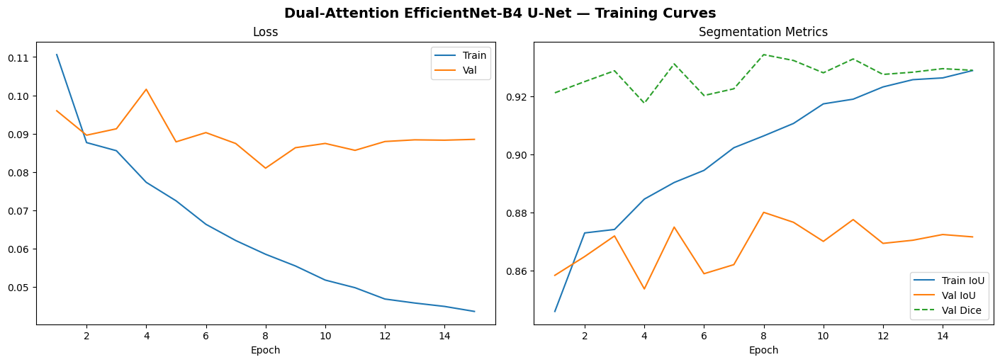

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Train Dual-Attention EfficientNet-B4 U-Net model
# IMPROVEMENT: warmup scheduler step, longer epochs, gradient clipping
# ════════════════════════════════════════════════════════════════════════════

best_dice_dual = 0.0
history = defaultdict(list)
BEST_THRESH_DUAL = 0.5   # will be updated after threshold search

print("\nTraining Dual-Attention EfficientNet-B4 U-Net model...")

for epoch in range(1, EPOCHS + 1):
    start_time = time.time()

    tr_loss, tr_iou = train_seg_epoch(
        dual_model, train_dl, optimizer, seg_criterion, DEVICE)

    va_loss, va_iou, va_dice, _, _, _, _ = eval_seg(
        dual_model, val_dl, seg_criterion, DEVICE)

    # ── IMPROVEMENT: warmup-cosine scheduler ──────────────────────────────────
    current_lr = scheduler.step()

    history["tr_loss"].append(tr_loss); history["va_loss"].append(va_loss)
    history["tr_iou"].append(tr_iou);   history["va_iou"].append(va_iou)
    history["va_dice"].append(va_dice)

    # ── Save best model checkpoint using validation Dice score ───────────────
    if va_dice > best_dice_dual:
        best_dice_dual = va_dice
        torch.save(dual_model.state_dict(), "/content/dual_attention_effb4_unet_best.pth")

    elapsed = time.time() - start_time
    seg_str = f"Seg IoU={va_iou:.4f} Dice={va_dice:.4f}"
    print(f"Epoch {epoch:03d}/{EPOCHS} | Loss={va_loss:.4f} | {seg_str} | LR={current_lr:.2e} | {elapsed:.1f}s")

clear_gpu()

# ── IMPROVEMENT: Threshold search on validation set ───────────────────────────
if TUNE_THRESHOLD:
    print("\nSearching for optimal segmentation threshold...")
    dual_model.load_state_dict(torch.load("/content/dual_attention_effb4_unet_best.pth", map_location=DEVICE))
    # Wrap for find_best_threshold (expects model(x) -> (seg_logits, extra))
    class _DualAttnWrapper(nn.Module):
        def __init__(self, m): super().__init__(); self.m = m
        def forward(self, x):
            seg = self.m(x)
            cls = torch.zeros(x.shape[0], 2, device=x.device)
            return seg, cls
    wrapped_dual = _DualAttnWrapper(dual_model)
    BEST_THRESH_DUAL, best_val_dice = find_best_threshold(wrapped_dual, val_dl, DEVICE)
    del wrapped_dual
else:
    BEST_THRESH_DUAL = 0.5

# Training curves
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)

axes[0].plot(epochs_range, history["tr_loss"], label="Train")
axes[0].plot(epochs_range, history["va_loss"], label="Val")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(epochs_range, history["tr_iou"],  label="Train IoU")
axes[1].plot(epochs_range, history["va_iou"],  label="Val IoU")
axes[1].plot(epochs_range, history["va_dice"], label="Val Dice", linestyle="--")
axes[1].set_title("Segmentation Metrics"); axes[1].set_xlabel("Epoch"); axes[1].legend()

fig.suptitle("Dual-Attention EfficientNet-B4 U-Net — Training Curves", fontsize=14, fontweight="bold")
plt.savefig("/content/dual_attention_effb4_unet_training_curves.png", dpi=150)
plt.show()

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Test evaluation for Dual-Attention EfficientNet-B4 U-Net model
# IMPROVEMENT: TTA at inference + optimal threshold
# ════════════════════════════════════════════════════════════════════════════

print("\n" + "═"*70)
print("DUAL-ATTENTION EFFICIENTNET-B4 U-NET TEST EVALUATION")
print("═"*70)

dual_model.load_state_dict(torch.load("/content/dual_attention_effb4_unet_best.pth", map_location=DEVICE))
dual_model.eval()

seg_tp = 0; seg_fp = 0; seg_fn = 0; seg_tn = 0

print(f"Inference with TTA={USE_TTA}, threshold={BEST_THRESH_DUAL:.2f}")

if USE_TTA:
    # ── IMPROVEMENT: TTA path ─────────────────────────────────────────────────
    for imgs, masks, labels in tqdm(test_dl, desc="Test TTA inference"):
        for b in range(imgs.shape[0]):
            avg_prob = tta_seg_logits(dual_model, imgs[b], DEVICE)
            pred = (avg_prob > BEST_THRESH_DUAL).long().cpu()
            gt   = masks[b]
            tp = int(((pred == 1) & (gt == 1)).sum())
            fp = int(((pred == 1) & (gt == 0)).sum())
            fn = int(((pred == 0) & (gt == 1)).sum())
            tn = int(((pred == 0) & (gt == 0)).sum())
            seg_tp += tp; seg_fp += fp; seg_fn += fn; seg_tn += tn
else:
    with torch.no_grad():
        for imgs, masks, labels in tqdm(test_dl, desc="Test inference"):
            imgs        = imgs.to(DEVICE, non_blocking=True)
            masks_dev   = masks.to(DEVICE, non_blocking=True)
            with autocast_context():
                seg_logits = dual_model(imgs)
            _, _, _, tp, fp, fn, tn = seg_metrics_batch(
                seg_logits, masks_dev, BEST_THRESH_DUAL)
            seg_tp += tp; seg_fp += fp; seg_fn += fn; seg_tn += tn
            del imgs, masks_dev, seg_logits

clear_gpu()

seg_cm = np.array([[seg_tn, seg_fp], [seg_fn, seg_tp]])
total_pixels = seg_cm.sum()
seg_iou  = seg_tp / (seg_tp + seg_fp + seg_fn + 1e-6)
seg_dice = 2 * seg_tp / (2 * seg_tp + seg_fp + seg_fn + 1e-6)
seg_acc  = (seg_tp + seg_tn) / (total_pixels + 1e-6)
seg_prec = seg_tp / (seg_tp + seg_fp + 1e-6)
seg_rec  = seg_tp / (seg_tp + seg_fn + 1e-6)
seg_f1   = 2 * seg_prec * seg_rec / (seg_prec + seg_rec + 1e-6)

print("\nDual-Attention EfficientNet-B4 U-Net Segmentation metrics:")
print(f"IoU       : {seg_iou:.4f}")
print(f"Dice      : {seg_dice:.4f}")
print(f"Accuracy  : {seg_acc:.4f}")
print(f"Precision : {seg_prec:.4f}")
print(f"Recall    : {seg_rec:.4f}")
print(f"F1        : {seg_f1:.4f}")


══════════════════════════════════════════════════════════════════════
DUAL-ATTENTION EFFICIENTNET-B4 U-NET TEST EVALUATION
══════════════════════════════════════════════════════════════════════
Inference with TTA=True, threshold=0.48


Test TTA inference: 100%|██████████| 42/42 [00:24<00:00,  1.71it/s]



Dual-Attention EfficientNet-B4 U-Net Segmentation metrics:
IoU       : 0.9056
Dice      : 0.9505
Accuracy  : 0.9731
Precision : 0.9464
Recall    : 0.9546
F1        : 0.9505


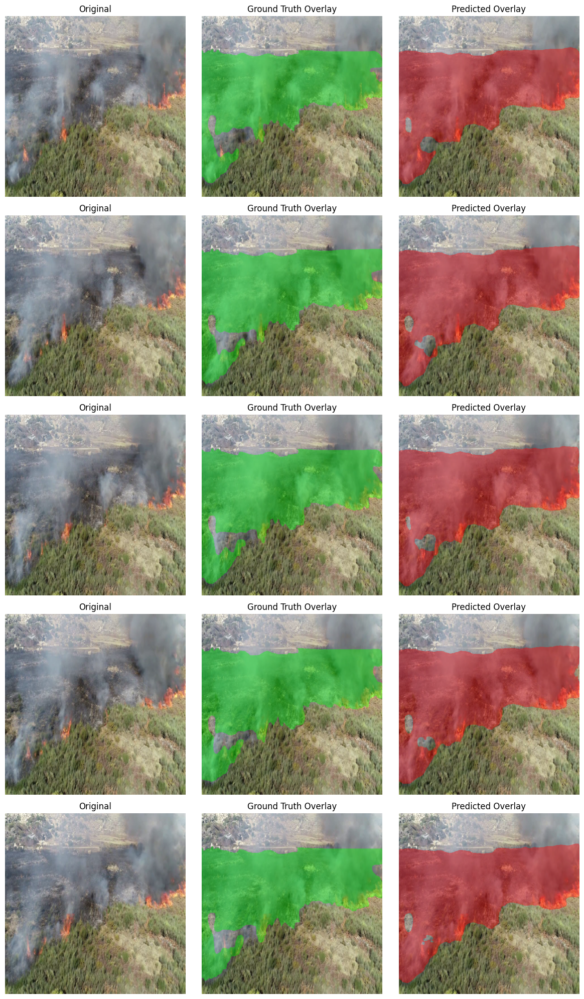

In [ ]:
import matplotlib.pyplot as plt
import torch
import numpy as np

num_samples = 5

dual_model.eval()

fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4*num_samples))

sample_count = 0

with torch.no_grad():

    for imgs, masks, _ in test_dl:

        imgs = imgs.to(DEVICE)

        seg_logits = dual_model(imgs)
        probs = torch.sigmoid(seg_logits.squeeze(1))
        preds = (probs > BEST_THRESH_DUAL).float()

        for b in range(imgs.shape[0]):

            if sample_count >= num_samples:
                break

            # ===== Original image =====
            img = imgs[b].cpu()

            mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
            std = torch.tensor(IMAGENET_STD).view(3,1,1)

            img = (img * std + mean).clamp(0,1)
            img = img.permute(1,2,0).numpy()

            gt_mask = masks[b].cpu().numpy()
            pred_mask = preds[b].cpu().numpy()

            # ===== Ground Truth Overlay =====
            gt_overlay = img.copy()
            gt_overlay[gt_mask == 1] = (
                0.6 * gt_overlay[gt_mask == 1]
                + 0.4 * np.array([0,1,0])     # Green
            )

            # ===== Predicted Overlay =====
            pred_overlay = img.copy()
            pred_overlay[pred_mask == 1] = (
                0.6 * pred_overlay[pred_mask == 1]
                + 0.4 * np.array([1,0,0])     # Red
            )

            # Plot
            axes[sample_count,0].imshow(img)
            axes[sample_count,0].set_title("Original")
            axes[sample_count,0].axis('off')

            axes[sample_count,1].imshow(gt_overlay)
            axes[sample_count,1].set_title("Ground Truth Overlay")
            axes[sample_count,1].axis('off')

            axes[sample_count,2].imshow(pred_overlay)
            axes[sample_count,2].set_title("Predicted Overlay")
            axes[sample_count,2].axis('off')

            sample_count += 1

        if sample_count >= num_samples:
            break

plt.tight_layout()

plt.savefig(
    "/content/segmentation_overlay_visualization.png",
    dpi=300,
    bbox_inches='tight'
)

plt.show()


# **Comparison**

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Standalone EfficientNet-B4 segmentation model
# IMPROVEMENT: CombinedSegLoss + warmup + threshold tuning
# ════════════════════════════════════════════════════════════════════════════

print("\n" + "═"*70)
print("STANDALONE EFFICIENTNET-B4 U-NET — SEGMENTATION ONLY")
print("═"*70)
clear_gpu()

seg_only_model = smp.Unet(
    encoder_name="efficientnet-b4",
    encoder_weights="imagenet",
    in_channels=3, classes=1, activation=None
).to(DEVICE)

opt_seg  = optim.AdamW(seg_only_model.parameters(), lr=1e-4, weight_decay=1e-4)
# ── IMPROVEMENT: CombinedSegLoss ──────────────────────────────────────────────
crit_seg = CombinedSegLoss()
# ── IMPROVEMENT: Warmup cosine ────────────────────────────────────────────────
sch_seg  = WarmupCosineScheduler(opt_seg, warmup_epochs=WARMUP_EPOCHS,
                                  total_epochs=EPOCHS, base_lr=1e-4, min_lr=1e-6)

seg_best_iou = 0.0
BEST_THRESH_SEG = 0.5

for ep in range(1, EPOCHS + 1):
    train_seg_epoch(seg_only_model, train_dl, opt_seg, crit_seg, DEVICE)
    va_loss, va_iou, va_dice, *_ = eval_seg(seg_only_model, val_dl, crit_seg, DEVICE)
    sch_seg.step()
    if va_iou > seg_best_iou:
        seg_best_iou = va_iou
        torch.save(seg_only_model.state_dict(), "/content/effb4_seg_best.pth")
    print(f"[EffB4-Seg] Epoch {ep:03d}/{EPOCHS} | Val IoU={va_iou:.4f} Dice={va_dice:.4f}")

# ── IMPROVEMENT: threshold tuning for seg-only model ─────────────────────────
if TUNE_THRESHOLD:
    seg_only_model.load_state_dict(torch.load("/content/effb4_seg_best.pth", map_location=DEVICE))
    # Wrap for find_best_threshold (which calls model returning seg_logits, cls_logits)
    class _SegWrapper(nn.Module):
        def __init__(self, m): super().__init__(); self.m = m
        def forward(self, x):
            seg = self.m(x)
            cls = torch.zeros(x.shape[0], 2, device=x.device)
            return seg, cls
    wrapped = _SegWrapper(seg_only_model)
    BEST_THRESH_SEG, _ = find_best_threshold(wrapped, val_dl, DEVICE)
    del wrapped
else:
    BEST_THRESH_SEG = 0.5

clear_gpu()


══════════════════════════════════════════════════════════════════════
STANDALONE EFFICIENTNET-B4 U-NET — SEGMENTATION ONLY
══════════════════════════════════════════════════════════════════════
[EffB4-Seg] Epoch 001/15 | Val IoU=0.8364 Dice=0.9082
[EffB4-Seg] Epoch 002/15 | Val IoU=0.8604 Dice=0.9220
[EffB4-Seg] Epoch 003/15 | Val IoU=0.8621 Dice=0.9234
[EffB4-Seg] Epoch 004/15 | Val IoU=0.8616 Dice=0.9228
[EffB4-Seg] Epoch 005/15 | Val IoU=0.8619 Dice=0.9233
[EffB4-Seg] Epoch 006/15 | Val IoU=0.8749 Dice=0.9312
[EffB4-Seg] Epoch 007/15 | Val IoU=0.8621 Dice=0.9235
[EffB4-Seg] Epoch 008/15 | Val IoU=0.8723 Dice=0.9295
[EffB4-Seg] Epoch 009/15 | Val IoU=0.8692 Dice=0.9278
[EffB4-Seg] Epoch 010/15 | Val IoU=0.8717 Dice=0.9290
[EffB4-Seg] Epoch 011/15 | Val IoU=0.8742 Dice=0.9307
[EffB4-Seg] Epoch 012/15 | Val IoU=0.8739 Dice=0.9302
[EffB4-Seg] Epoch 013/15 | Val IoU=0.8776 Dice=0.9326
[EffB4-Seg] Epoch 014/15 | Val IoU=0.8800 Dice=0.9342
[EffB4-Seg] Epoch 015/15 | Val IoU=0.8778 Dice=0

In [ ]:
# Test evaluation of standalone EfficientNet-B4 U-Net using one global confusion matrix

print("\n" + "═"*70)
print("TEST EVALUATION — STANDALONE EFFICIENTNET-B4 U-NET")
print("═"*70)

seg_only_model.load_state_dict(
    torch.load("/content/effb4_seg_best.pth", map_location=DEVICE))
seg_only_model.eval()

_, _, _, tp, fp, fn, tn = eval_seg(
    seg_only_model, test_dl, crit_seg, DEVICE, threshold=BEST_THRESH_SEG)
total = tp + fp + fn + tn
precision = tp / (tp + fp + 1e-6)
recall = tp / (tp + fn + 1e-6)
metrics_effb4 = {
    "IoU": tp / (tp + fp + fn + 1e-6),
    "Dice": 2 * tp / (2 * tp + fp + fn + 1e-6),
    "Accuracy": (tp + tn) / (total + 1e-6),
    "Precision": precision,
    "Recall": recall,
    "F1 Score": 2 * precision * recall / (precision + recall + 1e-6),
}
n_params_seg = sum(p.numel() for p in seg_only_model.parameters())

print(f"Best Threshold : {BEST_THRESH_SEG:.3f}")
for name, value in metrics_effb4.items():
    print(f"{name:10s}: {value:.4f}")
print(f"Parameters (M): {n_params_seg/1e6:.2f} M")


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch

# Load best model
seg_only_model.load_state_dict(
    torch.load("/content/effb4_seg_best.pth", map_location=DEVICE)
)
seg_only_model.eval()

num_samples = 5

fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4*num_samples))

sample_idx = 0

with torch.no_grad():

    for imgs, masks, _ in test_dl:

        imgs = imgs.to(DEVICE)

        # Prediction
        logits = seg_only_model(imgs)
        probs = torch.sigmoid(logits.squeeze(1))
        preds = (probs > BEST_THRESH_SEG).float()

        for b in range(imgs.shape[0]):

            if sample_idx >= num_samples:
                break

            # Original image (de-normalize)
            img = imgs[b].cpu()

            mean = torch.tensor(IMAGENET_MEAN).view(3,1,1)
            std = torch.tensor(IMAGENET_STD).view(3,1,1)

            img = (img * std + mean).clamp(0,1)
            img = img.permute(1,2,0).numpy()

            gt_mask = masks[b].cpu().numpy()
            pred_mask = preds[b].cpu().numpy()

            # Ground truth overlay (green)
            gt_overlay = img.copy()
            gt_overlay[gt_mask == 1] = (
                0.6 * gt_overlay[gt_mask == 1]
                + 0.4 * np.array([0,1,0])
            )

            # Predicted overlay (red)
            pred_overlay = img.copy()
            pred_overlay[pred_mask == 1] = (
                0.6 * pred_overlay[pred_mask == 1]
                + 0.4 * np.array([1,0,0])
            )

            # Plot
            axes[sample_idx,0].imshow(img)
            axes[sample_idx,0].set_title("Original")
            axes[sample_idx,0].axis("off")

            axes[sample_idx,1].imshow(gt_overlay)
            axes[sample_idx,1].set_title("Ground Truth Overlay")
            axes[sample_idx,1].axis("off")

            axes[sample_idx,2].imshow(pred_overlay)
            axes[sample_idx,2].set_title("Predicted Overlay")
            axes[sample_idx,2].axis("off")

            sample_idx += 1

        if sample_idx >= num_samples:
            break

plt.tight_layout()

plt.savefig(
    "/content/EffB4_UNet_segmentation_overlay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **UNet+ResNet 50**

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# UNet + ResNet50 — Segmentation Model
# Same improvements: CombinedSegLoss, warmup cosine, TTA, threshold tuning,
# gradient clipping — matching Dual-Head & EffB4-UNet pattern exactly.
# ════════════════════════════════════════════════════════════════════════════

print("\n" + "═"*70)
print("STANDALONE RESNET50 U-NET — SEGMENTATION ONLY")
print("═"*70)
clear_gpu()

resnet_model = smp.Unet(
    encoder_name="resnet50",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(DEVICE)

n_params_resnet = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)
print(f"ResNet50 U-Net trainable parameters: {n_params_resnet:,}")

# ── Same loss / optimiser / scheduler pattern as EffB4-UNet ─────────────────
opt_resnet  = optim.AdamW(resnet_model.parameters(), lr=1e-4, weight_decay=1e-4)
crit_resnet = CombinedSegLoss()
sch_resnet  = WarmupCosineScheduler(
    opt_resnet,
    warmup_epochs=WARMUP_EPOCHS,
    total_epochs=EPOCHS,
    base_lr=1e-4,
    min_lr=1e-6
)

resnet_best_iou = 0.0
BEST_THRESH_RESNET = 0.5
resnet_history = defaultdict(list)

for ep in range(1, EPOCHS + 1):
    start = time.time()
    tr_loss, tr_iou = train_seg_epoch(
        resnet_model, train_dl, opt_resnet, crit_resnet, DEVICE)
    va_loss, va_iou, va_dice, *_ = eval_seg(
        resnet_model, val_dl, crit_resnet, DEVICE)
    sch_resnet.step()

    resnet_history["tr_loss"].append(tr_loss)
    resnet_history["va_loss"].append(va_loss)
    resnet_history["tr_iou"].append(tr_iou)
    resnet_history["va_iou"].append(va_iou)
    resnet_history["va_dice"].append(va_dice)

    if va_iou > resnet_best_iou:
        resnet_best_iou = va_iou
        torch.save(resnet_model.state_dict(), "/content/resnet50_seg_best.pth")

    elapsed = time.time() - start
    print(f"[ResNet50-Seg] Epoch {ep:03d}/{EPOCHS} | "
          f"Loss={va_loss:.4f} | IoU={va_iou:.4f} | Dice={va_dice:.4f} | "
          f"{elapsed:.1f}s")

# ── Threshold tuning (same wrapper trick used for EffB4-UNet) ────────────────
if TUNE_THRESHOLD:
    resnet_model.load_state_dict(
        torch.load("/content/resnet50_seg_best.pth", map_location=DEVICE))
    class _ResNetWrapper(nn.Module):
        def __init__(self, m):
            super().__init__()
            self.m = m
        def forward(self, x):
            seg = self.m(x)
            cls = torch.zeros(x.shape[0], 2, device=x.device)
            return seg, cls
    wrapped_resnet = _ResNetWrapper(resnet_model)
    BEST_THRESH_RESNET, best_resnet_val_dice = find_best_threshold(
        wrapped_resnet, val_dl, DEVICE)
    del wrapped_resnet
else:
    BEST_THRESH_RESNET = 0.5

clear_gpu()

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# # TEST EVALUATION — ResNet50 U-Net
# # Same TTA wrapper + optimal threshold as other models
# ════════════════════════════════════════════════════════════════════════════

print("\n" + "═"*70)
print("TEST EVALUATION — RESNET50 U-NET")
print("═"*70)

resnet_model.load_state_dict(
    torch.load("/content/resnet50_seg_best.pth", map_location=DEVICE))
resnet_model.eval()

if USE_TTA:
    seg_tp = 0; seg_fp = 0; seg_fn = 0; seg_tn = 0

    for imgs, masks, _ in tqdm(test_dl, desc="ResNet50 TTA inference"):
        for b in range(imgs.shape[0]):
            # -- TTA: same 4-orientation average as dual-head -----------------
            img_t = imgs[b].to(DEVICE)
            augmented_imgs = [
                img_t.unsqueeze(0),
                torch.flip(img_t.unsqueeze(0), dims=[3]),   # H flip
                torch.flip(img_t.unsqueeze(0), dims=[2]),   # V flip
                torch.flip(img_t.unsqueeze(0), dims=[2, 3]) # HV flip
            ]
            with torch.no_grad():
                preds = []
                for aug_img in augmented_imgs:
                    with autocast_context():
                        seg_out = resnet_model(aug_img)
                    preds.append(torch.sigmoid(seg_out.squeeze(1)))
                # Undo flips
                preds[1] = torch.flip(preds[1], dims=[2])
                preds[2] = torch.flip(preds[2], dims=[1])
                preds[3] = torch.flip(preds[3], dims=[1, 2])
                avg_prob = torch.stack(preds, dim=0).mean(dim=0)

            pred = (avg_prob > BEST_THRESH_RESNET).long().cpu()
            gt   = masks[b]
            seg_tp += int(((pred == 1) & (gt == 1)).sum())
            seg_fp += int(((pred == 1) & (gt == 0)).sum())
            seg_fn += int(((pred == 0) & (gt == 1)).sum())
            seg_tn += int(((pred == 0) & (gt == 0)).sum())

else:
    te_loss, te_iou, te_dice, seg_tp, seg_fp, seg_fn, seg_tn = eval_seg(
        resnet_model, test_dl, crit_resnet, DEVICE, threshold=BEST_THRESH_RESNET)

clear_gpu()

# ── Metrics ──────────────────────────────────────────────────────────────────
total_px       = seg_tp + seg_fp + seg_fn + seg_tn
resnet_iou     = seg_tp / (seg_tp + seg_fp + seg_fn + 1e-6)
resnet_dice    = 2 * seg_tp / (2 * seg_tp + seg_fp + seg_fn + 1e-6)
resnet_acc     = (seg_tp + seg_tn) / (total_px + 1e-6)
resnet_prec    = seg_tp / (seg_tp + seg_fp + 1e-6)
resnet_rec     = seg_tp / (seg_tp + seg_fn + 1e-6)
resnet_f1      = 2 * resnet_prec * resnet_rec / (resnet_prec + resnet_rec + 1e-6)

print(f"\nResNet50 U-Net — Test Results (TTA={USE_TTA}, thresh={BEST_THRESH_RESNET:.2f})")
print(f"IoU       : {resnet_iou:.4f}")
print(f"Dice      : {resnet_dice:.4f}")
print(f"Accuracy  : {resnet_acc:.4f}")
print(f"Precision : {resnet_prec:.4f}")
print(f"Recall    : {resnet_rec:.4f}")
print(f"F1        : {resnet_f1:.4f}")
print(f"Parameters: {n_params_resnet/1e6:.2f} M")


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# QUALITATIVE: Overlay visualisation (5 test samples)
# ════════════════════════════════════════════════════════════════════════════

resnet_model.load_state_dict(
    torch.load("/content/resnet50_seg_best.pth", map_location=DEVICE))
resnet_model.eval()

num_samples = 5
fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))
sample_idx = 0

with torch.no_grad():
    for imgs, masks, _ in test_dl:
        imgs = imgs.to(DEVICE)
        logits = resnet_model(imgs)
        probs  = torch.sigmoid(logits.squeeze(1))
        preds  = (probs > BEST_THRESH_RESNET).float()

        for b in range(imgs.shape[0]):
            if sample_idx >= num_samples:
                break

            img = imgs[b].cpu()
            mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
            std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
            img  = (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

            gt_mask   = masks[b].cpu().numpy()
            pred_mask = preds[b].cpu().numpy()

            gt_overlay   = img.copy()
            pred_overlay = img.copy()
            gt_overlay[gt_mask == 1]     = (0.6 * gt_overlay[gt_mask == 1]
                                             + 0.4 * np.array([0, 1, 0]))
            pred_overlay[pred_mask == 1] = (0.6 * pred_overlay[pred_mask == 1]
                                             + 0.4 * np.array([1, 0, 0]))

            axes[sample_idx, 0].imshow(img)
            axes[sample_idx, 0].set_title("Original"); axes[sample_idx, 0].axis("off")
            axes[sample_idx, 1].imshow(gt_overlay)
            axes[sample_idx, 1].set_title("Ground Truth (green)"); axes[sample_idx, 1].axis("off")
            axes[sample_idx, 2].imshow(pred_overlay)
            axes[sample_idx, 2].set_title("Predicted (red)"); axes[sample_idx, 2].axis("off")

            sample_idx += 1

        if sample_idx >= num_samples:
            break

plt.tight_layout()
plt.savefig("/content/resnet50_segmentation_overlay.png", dpi=300, bbox_inches="tight")
plt.show()

# **UNet-DenseNet121**

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# UNet + DenseNet121 — Segmentation Model
# Same improvements: CombinedSegLoss, warmup cosine, TTA, threshold tuning,
# gradient clipping — matching Dual-Head & EffB4-UNet & ResNet50 pattern exactly.
# ════════════════════════════════════════════════════════════════════════════

print("\n" + "═"*70)
print("STANDALONE DENSENET121 U-NET — SEGMENTATION ONLY")
print("═"*70)
clear_gpu()

densenet_model = smp.Unet(
    encoder_name="densenet121",
    encoder_weights="imagenet",
    in_channels=3,
    classes=1,
    activation=None
).to(DEVICE)

n_params_densenet = sum(p.numel() for p in densenet_model.parameters() if p.requires_grad)
print(f"DenseNet121 U-Net trainable parameters: {n_params_densenet:,}")

# ── Same loss / optimiser / scheduler pattern as ResNet50-UNet ──────────────
opt_densenet  = optim.AdamW(densenet_model.parameters(), lr=1e-4, weight_decay=1e-4)
crit_densenet = CombinedSegLoss()
sch_densenet  = WarmupCosineScheduler(
    opt_densenet,
    warmup_epochs=WARMUP_EPOCHS,
    total_epochs=EPOCHS,
    base_lr=1e-4,
    min_lr=1e-6
)

densenet_best_iou = 0.0
BEST_THRESH_DENSENET = 0.5
densenet_history = defaultdict(list)

for ep in range(1, EPOCHS + 1):
    start = time.time()
    tr_loss, tr_iou = train_seg_epoch(
        densenet_model, train_dl, opt_densenet, crit_densenet, DEVICE)
    va_loss, va_iou, va_dice, *_ = eval_seg(
        densenet_model, val_dl, crit_densenet, DEVICE)
    sch_densenet.step()

    densenet_history["tr_loss"].append(tr_loss)
    densenet_history["va_loss"].append(va_loss)
    densenet_history["tr_iou"].append(tr_iou)
    densenet_history["va_iou"].append(va_iou)
    densenet_history["va_dice"].append(va_dice)

    if va_iou > densenet_best_iou:
        densenet_best_iou = va_iou
        torch.save(densenet_model.state_dict(), "/content/densenet121_seg_best.pth")

    elapsed = time.time() - start
    print(f"[DenseNet121-Seg] Epoch {ep:03d}/{EPOCHS} | "
          f"Loss={va_loss:.4f} | IoU={va_iou:.4f} | Dice={va_dice:.4f} | "
          f"{elapsed:.1f}s")

# ── Threshold tuning ─────────────────────────────────────────────────────────
if TUNE_THRESHOLD:
    densenet_model.load_state_dict(
        torch.load("/content/densenet121_seg_best.pth", map_location=DEVICE))
    class _DenseNetWrapper(nn.Module):
        def __init__(self, m):
            super().__init__()
            self.m = m
        def forward(self, x):
            seg = self.m(x)
            cls = torch.zeros(x.shape[0], 2, device=x.device)
            return seg, cls
    wrapped_densenet = _DenseNetWrapper(densenet_model)
    BEST_THRESH_DENSENET, best_densenet_val_dice = find_best_threshold(
        wrapped_densenet, val_dl, DEVICE)
    del wrapped_densenet
else:
    BEST_THRESH_DENSENET = 0.5

clear_gpu()


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# TEST EVALUATION — DenseNet121 U-Net
# Same TTA wrapper + optimal threshold as other models
# ════════════════════════════════════════════════════════════════════════════

print("\n" + "═"*70)
print("TEST EVALUATION — DENSENET121 U-NET")
print("═"*70)

densenet_model.load_state_dict(
    torch.load("/content/densenet121_seg_best.pth", map_location=DEVICE))
densenet_model.eval()

if USE_TTA:
    seg_tp = 0; seg_fp = 0; seg_fn = 0; seg_tn = 0

    for imgs, masks, _ in tqdm(test_dl, desc="DenseNet121 TTA inference"):
        for b in range(imgs.shape[0]):
            img_t = imgs[b].to(DEVICE)
            augmented_imgs = [
                img_t.unsqueeze(0),
                torch.flip(img_t.unsqueeze(0), dims=[3]),   # H flip
                torch.flip(img_t.unsqueeze(0), dims=[2]),   # V flip
                torch.flip(img_t.unsqueeze(0), dims=[2, 3]) # HV flip
            ]
            with torch.no_grad():
                preds = []
                for aug_img in augmented_imgs:
                    with autocast_context():
                        seg_out = densenet_model(aug_img)
                    preds.append(torch.sigmoid(seg_out.squeeze(1)))
                # Undo flips
                preds[1] = torch.flip(preds[1], dims=[2])
                preds[2] = torch.flip(preds[2], dims=[1])
                preds[3] = torch.flip(preds[3], dims=[1, 2])
                avg_prob = torch.stack(preds, dim=0).mean(dim=0)

            pred = (avg_prob > BEST_THRESH_DENSENET).long().cpu()
            gt   = masks[b]
            seg_tp += int(((pred == 1) & (gt == 1)).sum())
            seg_fp += int(((pred == 1) & (gt == 0)).sum())
            seg_fn += int(((pred == 0) & (gt == 1)).sum())
            seg_tn += int(((pred == 0) & (gt == 0)).sum())

else:
    te_loss, te_iou, te_dice, seg_tp, seg_fp, seg_fn, seg_tn = eval_seg(
        densenet_model, test_dl, crit_densenet, DEVICE, threshold=BEST_THRESH_DENSENET)

clear_gpu()

# ── Metrics ──────────────────────────────────────────────────────────────────
total_px         = seg_tp + seg_fp + seg_fn + seg_tn
densenet_iou     = seg_tp / (seg_tp + seg_fp + seg_fn + 1e-6)
densenet_dice    = 2 * seg_tp / (2 * seg_tp + seg_fp + seg_fn + 1e-6)
densenet_acc     = (seg_tp + seg_tn) / (total_px + 1e-6)
densenet_prec    = seg_tp / (seg_tp + seg_fp + 1e-6)
densenet_rec     = seg_tp / (seg_tp + seg_fn + 1e-6)
densenet_f1      = 2 * densenet_prec * densenet_rec / (densenet_prec + densenet_rec + 1e-6)

print(f"\nDenseNet121 U-Net — Test Results (TTA={USE_TTA}, thresh={BEST_THRESH_DENSENET:.2f})")
print(f"IoU       : {densenet_iou:.4f}")
print(f"Dice      : {densenet_dice:.4f}")
print(f"Accuracy  : {densenet_acc:.4f}")
print(f"Precision : {densenet_prec:.4f}")
print(f"Recall    : {densenet_rec:.4f}")
print(f"F1        : {densenet_f1:.4f}")
print(f"Parameters: {n_params_densenet/1e6:.2f} M")


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# QUALITATIVE: Overlay visualisation (5 test samples)
# ════════════════════════════════════════════════════════════════════════════

densenet_model.load_state_dict(
    torch.load("/content/densenet121_seg_best.pth", map_location=DEVICE))
densenet_model.eval()

num_samples = 5
fig, axes = plt.subplots(num_samples, 3, figsize=(12, 4 * num_samples))
sample_idx = 0

with torch.no_grad():
    for imgs, masks, _ in test_dl:
        imgs   = imgs.to(DEVICE)
        logits = densenet_model(imgs)
        probs  = torch.sigmoid(logits.squeeze(1))
        preds  = (probs > BEST_THRESH_DENSENET).float()

        for b in range(imgs.shape[0]):
            if sample_idx >= num_samples:
                break

            img  = imgs[b].cpu()
            mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
            std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
            img  = (img * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

            gt_mask   = masks[b].cpu().numpy()
            pred_mask = preds[b].cpu().numpy()

            gt_overlay   = img.copy()
            pred_overlay = img.copy()
            gt_overlay[gt_mask == 1]     = (0.6 * gt_overlay[gt_mask == 1]
                                             + 0.4 * np.array([0, 1, 0]))
            pred_overlay[pred_mask == 1] = (0.6 * pred_overlay[pred_mask == 1]
                                             + 0.4 * np.array([1, 0, 0]))

            axes[sample_idx, 0].imshow(img)
            axes[sample_idx, 0].set_title("Original"); axes[sample_idx, 0].axis("off")
            axes[sample_idx, 1].imshow(gt_overlay)
            axes[sample_idx, 1].set_title("Ground Truth (green)"); axes[sample_idx, 1].axis("off")
            axes[sample_idx, 2].imshow(pred_overlay)
            axes[sample_idx, 2].set_title("Predicted (red)"); axes[sample_idx, 2].axis("off")

            sample_idx += 1

        if sample_idx >= num_samples:
            break

plt.tight_layout()
plt.savefig("/content/densenet121_segmentation_overlay.png", dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Ablation Study on Attention Mechanism
# ════════════════════════════════════════════════════════════════════════════

print("\n" + "═"*70)
print("TABLE 6: ABLATION STUDY ON ATTENTION MECHANISM")
print("═"*70)


class AttentionAblationUNet(nn.Module):
    """
    EfficientNet-B4 U-Net with a *configurable* attention module applied to
    the deepest encoder feature map — mirrors DualAttentionEfficientNetB4UNet
    but allows channel-only / spatial-only / none, for ablation purposes.
    attention_mode: "channel", "spatial", or "none"
    """
    def __init__(self, attention_mode="channel", reduction=16, spatial_kernel=7):
        super().__init__()
        assert attention_mode in ("channel", "spatial", "none")
        self.attention_mode = attention_mode

        self.seg_model = smp.Unet(
            encoder_name="efficientnet-b4",
            encoder_weights="imagenet",
            in_channels=3, classes=1, activation=None
        )
        encoder_channels = self.seg_model.encoder.out_channels[-1]

        if attention_mode == "channel":
            self.attn = ChannelAttention(encoder_channels, reduction=reduction)
        elif attention_mode == "spatial":
            self.attn = SpatialAttention(kernel_size=spatial_kernel)
        else:
            self.attn = nn.Identity()

    def _decode(self, features):
        try:
            return self.seg_model.decoder(features)
        except TypeError:
            return self.seg_model.decoder(*features)

    def forward(self, x):
        features = list(self.seg_model.encoder(x))
        if self.attention_mode == "none":
            fused = features[-1]
        else:
            fused = features[-1] + self.attn(features[-1])   # residual fusion
        features[-1] = fused
        decoder_output = self._decode(features)
        return self.seg_model.segmentation_head(decoder_output)


def _metrics_from_confusion(tp, fp, fn, tn):
    total = tp + fp + fn + tn
    iou  = tp / (tp + fp + fn + 1e-6)
    dice = 2 * tp / (2 * tp + fp + fn + 1e-6)
    acc  = (tp + tn) / (total + 1e-6)
    prec = tp / (tp + fp + 1e-6)
    rec  = tp / (tp + fn + 1e-6)
    f1   = 2 * prec * rec / (prec + rec + 1e-6)
    return {"IoU": iou, "Dice": dice, "Accuracy": acc,
            "Precision": prec, "Recall": rec, "F1 Score": f1}


def eval_checkpoint(model, ckpt_path, tag, threshold=0.5, use_tta=None):
    """Loads a checkpoint and evaluates it on test_dl with the SAME
    TTA / threshold convention used elsewhere in this notebook, returning
    clean, collision-free metrics (avoids the seg_iou/seg_dice/... variable
    reuse across model blocks earlier in the notebook)."""
    use_tta = USE_TTA if use_tta is None else use_tta
    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()
    seg_tp = seg_fp = seg_fn = seg_tn = 0
    with torch.no_grad():
        for imgs, masks, _ in tqdm(test_dl, desc=f"{tag} evaluation"):
            if use_tta:
                for b in range(imgs.shape[0]):
                    avg_prob = tta_seg_logits(model, imgs[b], DEVICE)
                    pred = (avg_prob > threshold).long().cpu()
                    gt   = masks[b]
                    seg_tp += int(((pred == 1) & (gt == 1)).sum())
                    seg_fp += int(((pred == 1) & (gt == 0)).sum())
                    seg_fn += int(((pred == 0) & (gt == 1)).sum())
                    seg_tn += int(((pred == 0) & (gt == 0)).sum())
            else:
                imgs_d = imgs.to(DEVICE)
                with autocast_context():
                    logits = model(imgs_d)
                probs = torch.sigmoid(logits.squeeze(1)).cpu()
                pred = (probs > threshold).long()
                seg_tp += int(((pred == 1) & (masks == 1)).sum())
                seg_fp += int(((pred == 1) & (masks == 0)).sum())
                seg_fn += int(((pred == 0) & (masks == 1)).sum())
                seg_tn += int(((pred == 0) & (masks == 0)).sum())
    clear_gpu()
    return _metrics_from_confusion(seg_tp, seg_fp, seg_fn, seg_tn)


def train_attention_variant(attention_mode, ckpt_path, tag):
    """Trains one attention-ablation variant end-to-end (same recipe as the
    proposed model) and returns its test-set metrics."""
    print(f"\n--- Training variant: {tag} ---")
    clear_gpu()
    model = AttentionAblationUNet(attention_mode=attention_mode).to(DEVICE)

    opt  = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    crit = CombinedSegLoss()
    sch  = WarmupCosineScheduler(opt, warmup_epochs=WARMUP_EPOCHS,
                                  total_epochs=EPOCHS, base_lr=1e-4, min_lr=1e-6)

    best_dice = 0.0
    for ep in range(1, EPOCHS + 1):
        start = time.time()
        tr_loss, tr_iou = train_seg_epoch(model, train_dl, opt, crit, DEVICE)
        va_loss, va_iou, va_dice, *_ = eval_seg(model, val_dl, crit, DEVICE)
        sch.step()
        if va_dice > best_dice:
            best_dice = va_dice
            torch.save(model.state_dict(), ckpt_path)
        print(f"[{tag}] Epoch {ep:03d}/{EPOCHS} | Loss={va_loss:.4f} | "
              f"IoU={va_iou:.4f} | Dice={va_dice:.4f} | {time.time()-start:.1f}s")
    clear_gpu()

    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()

    best_thresh = 0.5
    if TUNE_THRESHOLD:
        class _Wrap(nn.Module):
            def __init__(self, m): super().__init__(); self.m = m
            def forward(self, x):
                seg = self.m(x)
                cls = torch.zeros(x.shape[0], 2, device=x.device)
                return seg, cls
        best_thresh, _ = find_best_threshold(_Wrap(model), val_dl, DEVICE)

    return eval_checkpoint(model, ckpt_path, tag, threshold=best_thresh)


# ── Row 1: Baseline (no attention) — reuse checkpoint trained earlier ────────
row_baseline = eval_checkpoint(seg_only_model, "/content/effb4_seg_best.pth",
                                "EffB4-Baseline", threshold=BEST_THRESH_SEG)

# ── Row 2: + Channel Attention only — trained here ────────────────────────────
row_channel = train_attention_variant(
    "channel", "/content/effb4_channel_attn_best.pth", "EffB4+ChannelAttn")

# ── Row 3: + Spatial Attention only — trained here ────────────────────────────
row_spatial = train_attention_variant(
    "spatial", "/content/effb4_spatial_attn_best.pth", "EffB4+SpatialAttn")

# ── Row 4: Proposed Dual Attention (channel + spatial) — reuse checkpoint ────
row_dual = eval_checkpoint(dual_model, "/content/dual_attention_effb4_unet_best.pth",
                            "Dual-Attention (Proposed)", threshold=BEST_THRESH_DUAL)

table6 = pd.DataFrame([
    {"S.No": 1, "Model Variant": "EfficientNet-B4 U-Net Baseline",                 **row_baseline},
    {"S.No": 2, "Model Variant": "EfficientNet-B4 U-Net + Channel Attention",      **row_channel},
    {"S.No": 3, "Model Variant": "EfficientNet-B4 U-Net + Spatial Attention",      **row_spatial},
    {"S.No": 4, "Model Variant": "Proposed Dual Attention EfficientNet-B4 U-Net", **row_dual},
])
for c in ["IoU", "Dice", "Accuracy", "Precision", "Recall", "F1 Score"]:
    table6[c] = table6[c].round(4)

print("\nTable 6 — Ablation Study on Attention Mechanism")
display(table6)



In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# Ablation Study on Loss Function
# ════════════════════════════════════════════════════════════════════════════

print("\n" + "═"*70)
print("TABLE 8: ABLATION STUDY ON LOSS FUNCTION")
print("═"*70)


class BCEOnlyLoss(nn.Module):
    """Row 1: plain binary cross-entropy, no Dice/Focal/Tversky term."""
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits, targets):
        return self.bce(logits.squeeze(1), targets.float())


class BCEDiceFocalLoss(nn.Module):
    """
    Row 3: BCE-Dice + Focal, with the Tversky term dropped from the full
    CombinedSegLoss. Weights are renormalised from the paper's 0.40 : 0.30
    (BCE-Dice : Focal) ratio so they still sum to 1 -> 0.5714 : 0.4286.
    """
    def __init__(self):
        super().__init__()
        self.bce_dice = BCEDiceLoss(bce_weight=0.4)
        self.focal    = FocalLoss(alpha=0.8, gamma=2.0)
        self.w_bced   = 0.40 / 0.70
        self.w_focal  = 0.30 / 0.70

    def forward(self, logits, targets):
        return (self.w_bced  * self.bce_dice(logits, targets)
                + self.w_focal * self.focal(logits, targets))


def train_loss_variant(loss_fn, ckpt_path, tag):
    """Trains the PROPOSED dual-attention architecture with a given loss
    function and returns its test-set metrics (uses the same helpers —
    eval_checkpoint / _metrics_from_confusion — defined in the Table 6 cell;
    run that cell first)."""
    print(f"\n--- Training loss variant: {tag} ---")
    clear_gpu()
    model = DualAttentionEfficientNetB4UNet().to(DEVICE)

    opt = optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
    sch = WarmupCosineScheduler(opt, warmup_epochs=WARMUP_EPOCHS,
                                 total_epochs=EPOCHS, base_lr=1e-4, min_lr=1e-6)

    best_dice = 0.0
    for ep in range(1, EPOCHS + 1):
        start = time.time()
        tr_loss, tr_iou = train_seg_epoch(model, train_dl, opt, loss_fn, DEVICE)
        va_loss, va_iou, va_dice, *_ = eval_seg(model, val_dl, loss_fn, DEVICE)
        sch.step()
        if va_dice > best_dice:
            best_dice = va_dice
            torch.save(model.state_dict(), ckpt_path)
        print(f"[{tag}] Epoch {ep:03d}/{EPOCHS} | Loss={va_loss:.4f} | "
              f"IoU={va_iou:.4f} | Dice={va_dice:.4f} | {time.time()-start:.1f}s")
    clear_gpu()

    model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
    model.eval()

    best_thresh = 0.5
    if TUNE_THRESHOLD:
        class _Wrap(nn.Module):
            def __init__(self, m): super().__init__(); self.m = m
            def forward(self, x):
                seg = self.m(x)
                cls = torch.zeros(x.shape[0], 2, device=x.device)
                return seg, cls
        best_thresh, _ = find_best_threshold(_Wrap(model), val_dl, DEVICE)

    return eval_checkpoint(model, ckpt_path, tag, threshold=best_thresh)


# ── Row 1: BCE Loss Only ──────────────────────────────────────────────────────
row_bce = train_loss_variant(
    BCEOnlyLoss(), "/content/effb4_dual_bce_only_best.pth", "BCE-Only")

# ── Row 2: BCE + Dice Loss ────────────────────────────────────────────────────
row_bce_dice = train_loss_variant(
    BCEDiceLoss(bce_weight=0.4), "/content/effb4_dual_bcedice_best.pth", "BCE+Dice")

# ── Row 3: BCE-Dice + Focal Loss ──────────────────────────────────────────────
row_bce_dice_focal = train_loss_variant(
    BCEDiceFocalLoss(), "/content/effb4_dual_bcedicefocal_best.pth", "BCE-Dice+Focal")

# ── Row 4: Combined BCE-Dice + Focal + Tversky (= proposed model) ────────────
row_combined = eval_checkpoint(
    dual_model, "/content/dual_attention_effb4_unet_best.pth",
    "Combined (Proposed)", threshold=BEST_THRESH_DUAL)

table8 = pd.DataFrame([
    {"S.No": 1, "Loss Function Variant": "BCE Loss Only",                              **row_bce},
    {"S.No": 2, "Loss Function Variant": "BCE + Dice Loss",                             **row_bce_dice},
    {"S.No": 3, "Loss Function Variant": "BCE-Dice + Focal Loss",                       **row_bce_dice_focal},
    {"S.No": 4, "Loss Function Variant": "Combined BCE-Dice + Focal + Tversky Loss",    **row_combined},
])
for c in ["IoU", "Dice", "Accuracy", "Precision", "Recall", "F1 Score"]:
    table8[c] = table8[c].round(4)

print("\nTable 8 — Ablation Study on Loss Function")
display(table8)



In [ ]:
# Paired per-image statistical analysis with bootstrap confidence intervals
# Run only after all four checkpoints have been produced by this notebook.

import importlib
if importlib.util.find_spec("scipy") is None:
    pip_install("scipy")
from scipy import stats

N_BOOTSTRAP = 10000

def per_image_confusions(model, loader, device, threshold, use_tta=None):
    use_tta = USE_TTA if use_tta is None else use_tta
    model.eval()
    tp_l, fp_l, fn_l, tn_l = [], [], [], []
    with torch.no_grad():
        for imgs, masks, _ in tqdm(loader, desc="Per-image evaluation"):
            for b in range(imgs.shape[0]):
                if use_tta:
                    prob = tta_seg_logits(model, imgs[b], device)
                    pred = (prob > threshold).long().cpu().squeeze(0)
                else:
                    image = imgs[b].unsqueeze(0).to(device)
                    with autocast_context():
                        logits = model(image)
                    pred = (torch.sigmoid(logits[0, 0]).cpu() > threshold).long()
                target = masks[b].long()
                tp_l.append(int(((pred == 1) & (target == 1)).sum()))
                fp_l.append(int(((pred == 1) & (target == 0)).sum()))
                fn_l.append(int(((pred == 0) & (target == 1)).sum()))
                tn_l.append(int(((pred == 0) & (target == 0)).sum()))
    return tuple(np.asarray(values) for values in (tp_l, fp_l, fn_l, tn_l))

def confusion_metrics(tp, fp, fn, tn):
    total = tp + fp + fn + tn
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    return {
        "IoU": tp / (tp + fp + fn + 1e-6),
        "Dice": 2 * tp / (2 * tp + fp + fn + 1e-6),
        "Accuracy": (tp + tn) / (total + 1e-6),
        "Precision": precision,
        "Recall": recall,
        "F1 Score": 2 * precision * recall / (precision + recall + 1e-6),
    }

def per_image_metrics(model, loader, device, threshold, use_tta=None):
    counts = per_image_confusions(model, loader, device, threshold, use_tta)
    return pd.DataFrame(confusion_metrics(*row) for row in zip(*counts))

def paired_bootstrap_difference(proposed, baseline, n_bootstrap=N_BOOTSTRAP, seed=SEED):
    proposed = np.asarray(proposed, dtype=float)
    baseline = np.asarray(baseline, dtype=float)
    if proposed.shape != baseline.shape:
        raise ValueError("Paired model outputs must cover the same test images.")
    differences = proposed - baseline
    rng = np.random.default_rng(seed)
    indices = rng.integers(0, len(differences), size=(n_bootstrap, len(differences)))
    sampled_means = differences[indices].mean(axis=1)
    low, high = np.quantile(sampled_means, [0.025, 0.975])
    nonzero = differences[~np.isclose(differences, 0)]
    p_value = np.nan if len(nonzero) == 0 else stats.wilcoxon(nonzero).pvalue
    return differences.mean(), low, high, p_value

proposed_metrics = per_image_metrics(dual_model, test_dl, DEVICE, BEST_THRESH_DUAL)
baselines = {
    "DenseNet121 U-Net": per_image_metrics(densenet_model, test_dl, DEVICE, BEST_THRESH_DENSENET),
    "ResNet50 U-Net": per_image_metrics(resnet_model, test_dl, DEVICE, BEST_THRESH_RESNET),
    "EfficientNet-B4 U-Net": per_image_metrics(seg_only_model, test_dl, DEVICE, BEST_THRESH_SEG),
}

rows = []
for baseline_name, baseline_metrics in baselines.items():
    for metric in proposed_metrics.columns:
        mean_diff, ci_low, ci_high, p_value = paired_bootstrap_difference(
            proposed_metrics[metric], baseline_metrics[metric])
        rows.append({
            "Comparison": f"Proposed vs {baseline_name}",
            "Metric": metric,
            "Mean paired difference": mean_diff,
            "95% CI low": ci_low,
            "95% CI high": ci_high,
            "Wilcoxon p-value": p_value,
        })

statistical_results = pd.DataFrame(rows)
display(statistical_results.round(4))
